# PSPNet trên Modal — ADE20K thật, một seed

1. Upload notebook này vào https://modal.com/notebooks.
2. Chọn GPU **L4** (hoặc lớn hơn như L40S/A100), CPU khoảng **4 cores**, RAM **16 GiB** trong Compute profile.
   Giữ **cùng một loại GPU** cho toàn bộ thí nghiệm (resume kiểm tra môi trường).
3. Attach một **Volume v2** tại **/mnt/pspnet-study-ade20k** (hoặc **/mnt/pspnet-study-ade20k-v2**);
   cell mục 2 tự nhận đường dẫn nào đang được gắn.
   Có thể tạo bằng CLI: `modal volume create pspnet-study-ade20k-v2 --version=2`.
4. Chạy tuần tự. Notebook tự tải **ADE20K** và **resnet101_v2.pth của tác giả** nếu chưa có.
5. Bước preflight chạy 3 update thật cho mỗi cấu hình để kiểm tra weights, gradient, VRAM và tốc độ;
   các update này bị bỏ đi, không thay đổi trọng số khởi tạo nghiên cứu.

Mặc định: một seed `17`, hai cấu hình b6/b7, 10.000 update mỗi bản với batch 16 (tổng 20.000), toàn bộ validation.
Trong lúc train có log chi tiết từng bước và đánh giá validation định kỳ; cuối cùng có bootstrap cho Δ mIoU.
Notebook chạy bằng GPU của kernel Modal. Dữ liệu, checkpoint và kết quả nằm trên Volume.
Không chạy đồng thời CLI và notebook vào cùng output. Xem thêm README.md.


# Nghiên cứu có kiểm soát: PPM {1,2,3,6} và {1,2,3,7}

Chỉ thay đầu ra pooling nhánh cuối 6×6 thành 7×7. Backbone ResNet-101, dilation,
output stride 8, số nhánh/kênh, segmentation head và auxiliary loss giữ như nhau.
Baseline và phiên bản thử nghiệm dùng cùng weights khởi tạo, dữ liệu/augmentation và ngân sách.
Ngân sách được rút gọn còn 10.000 bước mỗi bản (paper: 150.000) vì giới hạn GPU, nên mIoU tuyệt đối có thể
thấp hơn paper; kết luận dựa trên chênh lệch b7−b6 trong cùng điều kiện, paper chỉ là mốc tham chiếu.

Notebook này mặc định **ADE20K thật, 150 lớp, seed 17**; không chạy dữ liệu tổng hợp.
Một seed đủ để thực hiện cặp so sánh theo yêu cầu; kết quả không ước lượng biến thiên giữa seed.
Không có số liệu được điền sẵn và không khẳng định cấu hình mới tốt hơn.

Kiến trúc nhập từ hszhao/semseg tại commit `4f274c3f276778228bc14a4565822d46359f0cc8`.
PyTorch, augmentation PIL và BatchNorm cục bộ là điều kiện tái lập cần ghi trong báo cáo;
không tuyên bố tái tạo chính xác số liệu bài báo Caffe/đa GPU.

Nguồn: [paper](https://arxiv.org/abs/1612.01105),
[mã tác giả](https://github.com/hszhao/semseg), [ADE20K](https://ade20k.csail.mit.edu/).


## 1. Kiểm tra môi trường

Giữ PyTorch đang có trên Modal và cài các thư viện còn thiếu. Cần CUDA GPU cho ADE20K.
Train dùng AMP BF16 trên L4 để giảm VRAM; đánh giá/benchmark FP32, TF32 tắt.
Giữ cùng phần cứng/phần mềm cho hai bản. Nếu cần restart kernel sau cài đặt, restart rồi chạy lại.


In [1]:
import importlib.util
import subprocess
import sys
import shutil
from pathlib import Path

if importlib.util.find_spec("torch") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "torch>=2.5,<3"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install",
                "numpy>=1.26,<3", "pandas>=2,<4", "Pillow>=10,<13",
                "matplotlib>=3.8,<4", "fvcore==0.1.5.post20221221",
                "gdown==5.2.0", "modal>=1.6.1,<2"], check=True)
if shutil.which("git") is None:
    subprocess.run(["apt-get", "update"], check=True)
    subprocess.run(["apt-get", "install", "-y", "git"], check=True)
import torch
assert torch.cuda.is_available(), "Chọn GPU L4 trong Compute profile của Modal rồi restart kernel."
assert torch.cuda.is_bf16_supported(), "GPU phải hỗ trợ BF16, chẳng hạn L4/A100."
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory GiB:", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))


  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61399 sha256=a9bc742e7ee3dc6a2e09496a95acb05669c7944d2d1332d2c50b7dae2a059577
  Stored in directory: /tmp/pip-ephem-wheel-cache-hwz4kpeo/wheels/ed/9f/a5/e4f5b27454ccd4596bd8b62432c7d6b1ca9fa22aef9d70a16a
  Created wheel for iopath: filename=iopath-0.1.10-py3-none-any.whl size=31533 sha256=6a432abec629a967e23da8c1ce82857d54e47c2efd5a5b43f89199795d2b0baf
  Stored in directory: /tmp/pip-ephem-wheel-cache-hwz4kpeo/wheels/7c/96/04/4f5f31ff812f684f69f40cb1634357812220aac58d4698048c
Successfully built fvcore iopath



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Python: 3.12.6 (main, Sep 27 2024, 06:10:12) [GCC 12.2.0]
PyTorch: 2.8.0+cu129
GPU: NVIDIA L40S
GPU memory GiB: 44.4


## 2. Gắn Volume v2

Attach Volume v2 tại **/mnt/pspnet-study-ade20k** (ưu tiên, nơi dữ liệu đã tải) hoặc
**/mnt/pspnet-study-ade20k-v2** trước khi chạy. Cell dưới tự chọn đường dẫn đang được gắn.
Volume v2 cho phép đồng bộ dữ liệu bằng `sync -f` từ notebook/subprocess,
tránh SDK commit kéo theo reload khi log vẫn mở.
[Tài liệu Volume v2](https://modal.com/docs/guide/volumes).


In [2]:
import os
MOUNT_CANDIDATES = [Path("/mnt/pspnet-study-ade20k"), Path("/mnt/pspnet-study-ade20k-v2")]
VOLUME_MOUNT = next((p for p in MOUNT_CANDIDATES if p.is_dir()), None)
assert VOLUME_MOUNT is not None, f"Attach Volume v2 tại một trong {[str(p) for p in MOUNT_CANDIDATES]} trước."
WORK = VOLUME_MOUNT / "notebook_workspace"
WORK.mkdir(parents=True, exist_ok=True)
os.environ["PSPNET_MODAL_MOUNT"] = str(VOLUME_MOUNT)
os.chdir(WORK)
probe = WORK / ".write_probe"
probe.write_text("volume write test", encoding="utf-8")
probe.unlink()
subprocess.run(["sync", "-f", str(VOLUME_MOUNT)], check=True)
print("Persistent workspace:", WORK)


Persistent workspace: /mnt/pspnet-study-ade20k/notebook_workspace


## 3. Cấu hình một seed

Mặc định: ADE20K, seed 17, b6/b7, **10.000 optimizer updates** mỗi bản (~8 epoch; tổng 20.000 cho hai bản), batch thực **16**,
không accumulation, nên BatchNorm thấy 16 ảnh mỗi forward như batch 16 của paper. LR poly giảm về 0 đúng ở bước cuối.
Backbone luôn fine-tune. AMP BF16 và cuDNN autotune (`cudnn_benchmark`) áp dụng giống nhau cho cả hai bản khi train;
vì vậy train không tái lập từng bit, còn đánh giá/benchmark vẫn deterministic FP32.

`eval_every`/`eval_subset`: cứ 2.000 bước đánh giá nhanh trên 500 ảnh validation cố định (cùng ảnh cho hai bản)
để theo dõi quá trình học. Không dùng để chọn checkpoint: kết quả báo cáo luôn là checkpoint cuối.
Ngân sách ngắn: mô hình chưa hội tụ hoàn toàn, mIoU tuyệt đối sẽ thấp hơn paper rõ rệt;
chênh lệch nhỏ giữa b6/b7 cần đọc cùng khoảng tin cậy bootstrap ở mục 11b.
Nếu preflight báo thiếu VRAM: `batch_size=8`, `accumulation=2` (batch hiệu dụng vẫn 16) với `EXPERIMENT_NAME` mới.

`INIT_KIND="backbone"` tự tải ImageNet weights deep-stem của tác giả.
Nếu dùng `psp_checkpoint`, đặt đường dẫn checkpoint PSPNet tương thích vào `INITIAL_WEIGHTS`;
cả hai bản cùng được huấn luyện tiếp với optimizer reset và cùng ngân sách.

Preflight sẽ kiểm tra tài nguyên trên dữ liệu thật trước train dài. Nếu đổi crop/batch/GPU/precision,
đổi tên thí nghiệm và chạy lại cả hai. Không sửa cấu hình giữa hai lượt trong cùng thí nghiệm.


In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROFILE = "research"
EXPERIMENT_NAME = "ade20k_seed17_b16_10k_v4"
# True  = CHỈ train, đánh giá, benchmark b6_link (1236 + link) và b7_link (1237 + link).
# False = chạy b6 (1236) và b7 (1237) như bình thường.
# Công tắc này không đổi cấu hình huấn luyện bên dưới.
ENABLE_LINKS = True
DATA_ROOT = VOLUME_MOUNT / "datasets" / "ADEChallengeData2016"
INIT_KIND = "backbone"
INITIAL_WEIGHTS = VOLUME_MOUNT / "weights" / "resnet101_v2.pth"
OUTPUT_BASE = VOLUME_MOUNT / "results"

cfg = {
    "profile": PROFILE,
    "source_dir": str(WORK / "semseg"),
    "data_root": str(DATA_ROOT),
    "output_dir": str(OUTPUT_BASE / EXPERIMENT_NAME),
    "classes": 150,
    "init_kind": INIT_KIND,
    "initial_weights": str(INITIAL_WEIGHTS),
    "variants": ["b6", "b7"],  # cấu hình đã khóa; bản link chạy riêng ở mục 15
    "seeds": [17],
    "crop": 473,
    "batch_size": 16,
    "accumulation": 1,
    "max_steps": 10000,
    "lr": 0.01,
    "head_lr_multiplier": 10.0,
    "precision": "amp_bf16",
    "cudnn_benchmark": True,
    "scale_range": [0.5, 2.0],
    "rotation": 10.0,
    "save_every": 1000,
    "log_every": 50,
    "eval_crop": 473,
    "eval_base_size": 512,
    "val_limit": 0,
    "eval_every": 2000,
    "eval_subset": 500,
    "benchmark_size": 473,
    "benchmark_warmup": 100,
    "benchmark_repeats": 500,
    "benchmark_sessions": 5,
}
CONFIG_PATH = WORK / f"{EXPERIMENT_NAME}.json"
RESULTS = Path(cfg["output_dir"])
RUN_VARIANTS = ["b6_link", "b7_link"] if ENABLE_LINKS else cfg["variants"]
print(json.dumps(cfg, indent=2, ensure_ascii=False))
print("Sẽ train:", RUN_VARIANTS)
print("Batch hiệu dụng:", cfg["batch_size"] * cfg["accumulation"])


{
  "profile": "research",
  "source_dir": "/mnt/pspnet-study-ade20k/notebook_workspace/semseg",
  "data_root": "/mnt/pspnet-study-ade20k/datasets/ADEChallengeData2016",
  "output_dir": "/mnt/pspnet-study-ade20k/results/ade20k_seed17_b16_10k_v4",
  "classes": 150,
  "init_kind": "backbone",
  "initial_weights": "/mnt/pspnet-study-ade20k/weights/resnet101_v2.pth",
  "variants": [
    "b6",
    "b7"
  ],
  "seeds": [
    17
  ],
  "crop": 473,
  "batch_size": 16,
  "accumulation": 1,
  "max_steps": 10000,
  "lr": 0.01,
  "head_lr_multiplier": 10.0,
  "precision": "amp_bf16",
  "cudnn_benchmark": true,
  "scale_range": [
    0.5,
    2.0
  ],
  "rotation": 10.0,
  "save_every": 1000,
  "log_every": 50,
  "eval_crop": 473,
  "eval_base_size": 512,
  "val_limit": 0,
  "eval_every": 2000,
  "eval_subset": 500,
  "benchmark_size": 473,
  "benchmark_warmup": 100,
  "benchmark_repeats": 500,
  "benchmark_sessions": 5
}
Sẽ train: ['b6_link', 'b7_link']
Batch hiệu dụng: 16


## 4. Tải dữ liệu và pretrained weights

Giữ `DOWNLOAD_ADE20K=True` để tự tải ADEChallengeData2016 nếu dữ liệu chưa đầy đủ.
Việc tải chạy ở bước prepare sau khi mã Python đã được ghi.
Weights `resnet101_v2.pth` được tải từ file công khai trong thư mục chính thức của tác giả.
Nếu Google Drive giới hạn lượt tải, notebook đưa link/đường dẫn để tải thủ công rồi chạy lại.

Cấu trúc dataset: images/training, images/validation, annotations/training, annotations/validation.
Research yêu cầu 20.210 ảnh train, 2.000 ảnh validation. Nhãn raw 0 được ignore;
raw 1..150 chuyển thành class 0..149, không remap trước lần nữa.


In [4]:
DOWNLOAD_ADE20K = True
print("Dataset:", cfg["data_root"])
print("Weights:", cfg["initial_weights"])
print("Tải tự động nếu thiếu:", DOWNLOAD_ADE20K)


Dataset: /mnt/pspnet-study-ade20k/datasets/ADEChallengeData2016
Weights: /mnt/pspnet-study-ade20k/weights/resnet101_v2.pth
Tải tự động nếu thiếu: True


## 5. Ghi mã triển khai

Các cell mã phía dưới tự tạo `pspnet_lab.py` trong thư mục notebook.
Không cần tải kèm file Python. Mỗi nhiệm vụ sau đó chạy trong một tiến trình riêng,
để giải phóng model/optimizer khỏi VRAM giữa các lượt.

Điểm sửa kiến trúc nằm trong `make_model`: `bins` được truyền vào PSPNet ở cả train/eval.
`LinkedPPM` chỉ dùng khi bật extension: 6 cạnh có scalar học được, khởi tạo 0;
đặc trưng được trao đổi giữa các nhánh kề nhau ở độ phân giải thấp.


In [5]:
%%writefile pspnet_lab.py
"""Controlled PSPNet PPM study. Generated notebook embeds this file verbatim.

Architecture is imported from pinned hszhao/semseg (MIT), not torchvision.
Run `python pspnet_lab.py --help` for the notebook's subprocess interface.
"""
from __future__ import annotations

import argparse
from collections import deque
from concurrent.futures import ThreadPoolExecutor
import contextlib
import copy
import csv
import gc
import hashlib
import http.client
import json
import math
import os
from pathlib import Path
import random
import subprocess
import sys
import time
import urllib.request
import zipfile

import numpy as np
import pandas as pd
from PIL import Image, ImageFilter, ImageOps
import torch
from torch import nn
import torch.nn.functional as F

COMMIT = "4f274c3f276778228bc14a4565822d46359f0cc8"
ADE_URL = "https://data.csail.mit.edu/places/ADEchallenge/ADEChallengeData2016.zip"
BACKBONE_DRIVE_ID = "1V-sfLnqSuwTPgNMrqUp4HDZpqtoBH4xm"
VARIANTS = {"b6": ([1, 2, 3, 6], False), "b7": ([1, 2, 3, 7], False),
            "b6_link": ([1, 2, 3, 6], True), "b7_link": ([1, 2, 3, 7], True)}
MEAN = np.array([.485, .456, .406], dtype=np.float32)
STD = np.array([.229, .224, .225], dtype=np.float32)
PREFLIGHT_UPDATES = 3  # time the last one; the first includes cold start/cuDNN autotuning


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def json_write(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8", newline="\n")
    os.replace(tmp, path)


def atomic_save(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def append_csv(path, row):
    path = Path(path)
    new = not path.exists()
    with path.open("a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(row))
        if new:
            writer.writeheader()
        writer.writerow(row)


def utc_now():
    return time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())


def persist_volume():
    """Flush Volume v2 in notebooks/subprocesses without an implicit SDK reload."""
    mount = os.environ.get("PSPNET_MODAL_MOUNT")
    if mount:
        subprocess.run(["sync", "-f", mount], check=True, timeout=300)


def download_file(url, destination, attempts=3):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    partial = destination.with_suffix(destination.suffix + ".part")
    for attempt in range(attempts):
        try:
            offset = partial.stat().st_size if partial.exists() else 0
            request = urllib.request.Request(url, headers={"Range": f"bytes={offset}-"} if offset else {})
            with urllib.request.urlopen(request, timeout=60) as response:
                append = offset > 0 and response.status == 206
                mode = "ab" if append else "wb"
                received = offset if append else 0
                length = response.headers.get("Content-Length")
                expected = received + int(length) if length is not None else None
                last_report = received // (256 * 2**20)
                with partial.open(mode) as target:
                    while chunk := response.read(2**20):
                        target.write(chunk)
                        received += len(chunk)
                        report = received // (256 * 2**20)
                        if report > last_report:
                            print(f"Downloading {destination.name}: {received / 2**20:.0f} MiB", flush=True)
                            last_report = report
            if expected is not None and received != expected:
                raise OSError(f"Incomplete download: {received}/{expected} bytes")
            os.replace(partial, destination)
            return
        except (OSError, TimeoutError, http.client.HTTPException) as error:
            if getattr(error, "code", None) == 416 and partial.exists():
                # A prior process can finish the payload and stop before rename.
                with urllib.request.urlopen(urllib.request.Request(url, method="HEAD"), timeout=60) as response:
                    if int(response.headers.get("Content-Length", -1)) == partial.stat().st_size:
                        os.replace(partial, destination)
                        return
            if attempt + 1 == attempts:
                raise RuntimeError(f"Không tải được {url}. Tải thủ công vào {destination} rồi chạy lại.") from error
            print(f"Download retry {attempt + 1}: {error}", flush=True)


def resources(cfg, download_dataset=True):
    """Get real ADE20K and the author's matching ImageNet backbone weights."""
    if cfg["profile"] == "smoke":
        return
    weights = Path(cfg["initial_weights"])
    if not weights.is_file():
        if cfg["init_kind"] != "backbone" or weights.name != "resnet101_v2.pth":
            raise FileNotFoundError(f"Upload checkpoint vào {weights} trước khi chạy.")
        weights.parent.mkdir(parents=True, exist_ok=True)
        import gdown
        partial = weights.with_suffix(".pth.download")
        print("Tải resnet101_v2.pth từ Google Drive chính thức của hszhao...", flush=True)
        try:
            result = gdown.download(id=BACKBONE_DRIVE_ID, output=str(partial), quiet=False, resume=True)
            if not result or not partial.exists():
                raise RuntimeError("Google Drive returned no weights")
            # Reject HTML/error pages before treating the download as a checkpoint.
            if partial.stat().st_size < 1024 * 1024:
                raise ValueError("Downloaded file is too small to be ResNet-101")
            os.replace(partial, weights)
        except Exception as error:
            raise RuntimeError(f"Drive có thể giới hạn lượt tải. Tải file ID {BACKBONE_DRIVE_ID} thủ công vào {weights} rồi chạy lại.") from error
    # Validate BEFORE downloading/extracting the much larger dataset.
    setup_source(cfg["source_dir"])
    probe = make_model(cfg, "b6")
    if cfg["init_kind"] == "backbone":
        load_backbone(probe, cfg)
    else:
        probe.load_state_dict(load_external_state(weights), strict=True)
    del probe
    gc.collect()
    print("Pretrained weights tương thích.", flush=True)
    root = Path(cfg["data_root"])
    complete = all(len(list((root / "images" / split).glob("*.jpg"))) == count
                   and len(list((root / "annotations" / split).glob("*.png"))) == count
                   for split, count in [("training", 20210), ("validation", 2000)])
    if not complete:
        if not download_dataset:
            raise FileNotFoundError(f"ADE20K chưa đầy đủ tại {root}; bật download hoặc upload dataset.")
        archive = root.parent / "ADEChallengeData2016.zip"
        if not archive.is_file() or not zipfile.is_zipfile(archive):
            download_file(ADE_URL, archive)
        print("Giải nén ADE20K...", flush=True)
        with zipfile.ZipFile(archive) as z:
            for member in z.infolist():
                target = (root.parent / member.filename).resolve()
                if not target.is_relative_to(root.parent.resolve()):
                    raise ValueError("Unsafe archive path")
            z.extractall(root.parent)
    persist_volume()
    print("Tài nguyên ADE20K sẵn sàng:", root, flush=True)


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    # Bilinear/adaptive pooling backward can be nondeterministic on CUDA.
    # Warn rather than silently claim bitwise reproducibility.
    torch.use_deterministic_algorithms(True, warn_only=True)


def environment():
    return {"python": sys.version, "torch": str(torch.__version__), "numpy": np.__version__,
            "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
            "device_count": torch.cuda.device_count(), "source_commit": COMMIT}


def setup_source(root):
    root = Path(root).resolve()
    if not root.exists():
        subprocess.run(["git", "clone", "https://github.com/hszhao/semseg.git", str(root)], check=True)
    subprocess.run(["git", "-C", str(root), "checkout", "--detach", COMMIT], check=True, timeout=120)
    actual = subprocess.check_output(["git", "-C", str(root), "rev-parse", "HEAD"], text=True).strip()
    assert actual == COMMIT
    changes = subprocess.check_output(["git", "-C", str(root), "diff", "HEAD", "--", "model"], text=True)
    if changes:
        raise RuntimeError("Mã model upstream đã thay đổi. Dùng một thư mục source sạch.")


def import_source(cfg):
    source = str(Path(cfg["source_dir"]).resolve())
    if source not in sys.path:
        sys.path.insert(0, source)
    from model.pspnet import PSPNet
    from model.resnet import resnet101
    return PSPNet, resnet101


class LinkedPPM(nn.Module):
    """Six directed adjacent edges, applied simultaneously on low-res features."""
    def __init__(self, ppm):
        super().__init__()
        self.features = ppm.features
        self.edges = [(0, 1), (1, 0), (1, 2), (2, 1), (2, 3), (3, 2)]
        self.edge_weights = nn.Parameter(torch.zeros(len(self.edges)))

    def forward(self, x):
        z = [branch(x) for branch in self.features]
        mixed = list(z)
        for k, (src, dst) in enumerate(self.edges):
            size = z[dst].shape[-2:]
            if z[src].shape[-1] > size[-1]:
                aligned = F.adaptive_avg_pool2d(z[src], size)
            else:
                aligned = F.interpolate(z[src], size=size, mode="bilinear", align_corners=True)
            mixed[dst] = mixed[dst] + self.edge_weights[k].tanh() * aligned
        return torch.cat([x] + [F.interpolate(v, size=x.shape[-2:], mode="bilinear",
                                              align_corners=True) for v in mixed], dim=1)


def make_model(cfg, variant):
    PSPNet, _ = import_source(cfg)

    class ResearchPSPNet(PSPNet):
        # Keep upstream modules and state_dict names. Return logits for our trainer.
        def forward(self, x):
            size = x.shape[-2:]
            x = self.layer2(self.layer1(self.layer0(x)))
            aux_features = self.layer3(x)
            x = self.layer4(aux_features)
            logits = F.interpolate(self.cls(self.ppm(x)), size=size,
                                   mode="bilinear", align_corners=True)
            if self.training:
                aux = F.interpolate(self.aux(aux_features), size=size,
                                    mode="bilinear", align_corners=True)
                return logits, aux
            return logits

    bins, linked = VARIANTS[variant]
    model = ResearchPSPNet(layers=101, bins=tuple(bins), classes=cfg["classes"],
                           zoom_factor=8, pretrained=False)
    if linked:
        model.ppm = LinkedPPM(model.ppm)
    return model


def load_external_state(path):
    # Only tensor/state-dict checkpoints from a trusted source; no unsafe fallback.
    raw = torch.load(path, map_location="cpu", weights_only=True)
    if "state_dict" in raw:
        raw = raw["state_dict"]
    elif "model" in raw:
        raw = raw["model"]
    return {k.removeprefix("module."): v for k, v in raw.items()}


def load_backbone(model, cfg):
    _, resnet101 = import_source(cfg)
    backbone = resnet101(pretrained=False)
    weights = load_external_state(cfg["initial_weights"])
    # Classifier fc is unused by segmentation; enforce every actual backbone tensor.
    weights = {k: v for k, v in weights.items() if not k.startswith("fc.")}
    result = backbone.load_state_dict(weights, strict=False)
    assert set(result.missing_keys) == {"fc.weight", "fc.bias"} and not result.unexpected_keys, result
    for name, idx in [("conv1", 0), ("bn1", 1), ("conv2", 3), ("bn2", 4),
                      ("conv3", 6), ("bn3", 7)]:
        model.layer0[idx].load_state_dict(getattr(backbone, name).state_dict(), strict=True)
    for name in ("layer1", "layer2", "layer3", "layer4"):
        getattr(model, name).load_state_dict(getattr(backbone, name).state_dict(), strict=True)



Writing pspnet_lab.py


In [6]:
%%writefile -a pspnet_lab.py
def create_synthetic(root, classes):
    """Synthetic files only exercise the pipeline; never research evidence."""
    root = Path(root)
    for split, count in [("training", 8), ("validation", 3)]:
        for category in ("images", "annotations"):
            (root / category / split).mkdir(parents=True, exist_ok=True)
        rng = np.random.default_rng(2026 if split == "training" else 2027)
        for i in range(count):
            a = rng.integers(0, 256, (81, 97, 3), dtype=np.uint8)
            yy, xx = np.mgrid[:81, :97]
            mask = ((xx // 17 + yy // 21 + i) % classes + 1).astype(np.uint8)
            mask[:2] = 0
            Image.fromarray(a).save(root / "images" / split / f"demo_{i:03d}.jpg")
            Image.fromarray(mask).save(root / "annotations" / split / f"demo_{i:03d}.png")


def data_pairs(root, split):
    root = Path(root)
    pairs = [(p, root / "annotations" / split / (p.stem + ".png"))
             for p in sorted((root / "images" / split).glob("*.jpg"))]
    if not pairs or any(not y.exists() for _, y in pairs):
        raise FileNotFoundError(f"Thiếu ảnh/nhãn tại {root}, split={split}")
    return pairs


def read_mask(path, classes):
    raw = np.asarray(Image.open(path), dtype=np.int64)
    if raw.ndim != 2 or raw.min() < 0 or raw.max() > classes:
        raise ValueError(f"Nhãn phải là ADE gốc 0..{classes}: {path}")
    # ADE raw 0 = void; raw 1..150 -> train IDs 0..149.
    return np.where(raw == 0, 255, raw - 1).astype(np.uint8)


def tensor_image(image):
    a = np.asarray(image, dtype=np.float32) / 255.0
    return torch.from_numpy(((a - MEAN) / STD).transpose(2, 0, 1).copy())


def augment_pair(image_path, mask_path, cfg, seed, epoch, index):
    # Augmentation independent of model RNG, worker scheduling and variant.
    token = f"{seed}:{epoch}:{index}".encode()
    rng = random.Random(int.from_bytes(hashlib.sha256(token).digest()[:8], "little"))
    image = Image.open(image_path).convert("RGB")
    mask = Image.fromarray(read_mask(mask_path, cfg["classes"]))
    scale = rng.uniform(*cfg["scale_range"])
    size = (max(1, round(image.width * scale)), max(1, round(image.height * scale)))
    image = image.resize(size, Image.Resampling.BILINEAR)
    mask = mask.resize(size, Image.Resampling.NEAREST)
    angle = rng.uniform(-cfg["rotation"], cfg["rotation"])
    fill = tuple(int(round(v * 255)) for v in MEAN)
    image = image.rotate(angle, Image.Resampling.BILINEAR, fillcolor=fill)
    mask = mask.rotate(angle, Image.Resampling.NEAREST, fillcolor=255)
    if rng.random() < .5:
        image, mask = ImageOps.mirror(image), ImageOps.mirror(mask)
    if rng.random() < .5:
        image = image.filter(ImageFilter.GaussianBlur(radius=rng.uniform(.1, 1.5)))
    crop = cfg["crop"]
    border = (0, 0, max(0, crop - image.width), max(0, crop - image.height))
    image, mask = ImageOps.expand(image, border, fill), ImageOps.expand(mask, border, 255)
    left, top = rng.randint(0, image.width - crop), rng.randint(0, image.height - crop)
    box = (left, top, left + crop, top + crop)
    return tensor_image(image.crop(box)), torch.from_numpy(np.array(mask.crop(box), dtype=np.int64))


def batch_position(micro_index, n, batch, seed):
    batches = n // batch
    if batches == 0:
        raise ValueError("Dataset nhỏ hơn batch thực.")
    epoch, within = divmod(micro_index, batches)
    # Cheap for ADE20K; deterministic random access also makes resume exact in ordering.
    perm = np.random.default_rng(seed + epoch).permutation(n)
    return epoch, perm[within * batch:(within + 1) * batch]


def get_batch(pairs, cfg, seed, micro_index):
    epoch, ids = batch_position(micro_index, len(pairs), cfg["batch_size"], seed)
    samples = [augment_pair(*pairs[int(i)], cfg, seed, epoch, int(i)) for i in ids]
    return torch.stack([v[0] for v in samples]), torch.stack([v[1] for v in samples])


class BatchPrefetcher:
    """Build upcoming micro-batches in threads while the GPU trains (PIL releases the GIL).

    Returns exactly get_batch(pairs, cfg, seed, i) for i = first, first+1, ...,
    so data order, augmentation and resume position match the serial loader.
    """
    def __init__(self, pairs, cfg, seed, first, depth=8):
        self.args = (pairs, cfg, seed)
        self.pool = ThreadPoolExecutor(max_workers=min(4, os.cpu_count() or 1))
        self.queue = deque()
        self.next_index = first
        for _ in range(depth):
            self._submit()

    def _submit(self):
        self.queue.append((self.next_index, self.pool.submit(get_batch, *self.args, self.next_index)))
        self.next_index += 1

    def get(self, index):
        expected, future = self.queue.popleft()
        assert expected == index, "Prefetch order mismatch"
        self._submit()
        return future.result()

    def close(self):
        for _, future in self.queue:
            future.cancel()
        self.pool.shutdown(wait=True)



Appending to pspnet_lab.py


In [7]:
%%writefile -a pspnet_lab.py
def prepare(cfg):
    validate_config(cfg)
    setup_source(cfg["source_dir"])
    output = Path(cfg["output_dir"])
    output.mkdir(parents=True, exist_ok=True)
    if cfg["profile"] == "smoke":
        create_synthetic(cfg["data_root"], cfg["classes"])
    manifests = {}
    for split in ("training", "validation"):
        rows = []
        pairs = data_pairs(cfg["data_root"], split)
        if cfg["profile"] == "research":
            expected = 20210 if split == "training" else 2000
            if len(pairs) != expected:
                raise ValueError(f"Research ADE20K cần {expected} ảnh {split}, nhận {len(pairs)}.")
        for index, (image, mask) in enumerate(pairs):
            with Image.open(image) as im:
                size = im.size
            label = read_mask(mask, cfg["classes"])
            if label.shape != (size[1], size[0]):
                raise ValueError(f"Image/mask size mismatch: {image}")
            rows.append({"image": str(image.relative_to(cfg["data_root"])),
                         "mask": str(mask.relative_to(cfg["data_root"])),
                         "image_sha256": sha256(image), "mask_sha256": sha256(mask)})
            if (index + 1) % 1000 == 0:
                print("Hash/validate", split, index + 1, "/", len(pairs), flush=True)
        manifests[split] = rows
        print(split, len(rows), "ảnh đã kiểm tra", flush=True)
    # The official ADE20K split contains a few byte-identical train/val images.
    # Keep the official split (paper protocol, identical for every variant) and record them.
    train_by_hash = {}
    for r in manifests["training"]:
        train_by_hash.setdefault(r["image_sha256"], []).append(r["image"])
    duplicates = [{"validation": r["image"], "training": train_by_hash[r["image_sha256"]],
                   "image_sha256": r["image_sha256"]}
                  for r in manifests["validation"] if r["image_sha256"] in train_by_hash]
    if duplicates:
        print(f"CẢNH BÁO: {len(duplicates)} ảnh validation trùng byte với ảnh train trong split chính thức; "
              "giữ nguyên split và ghi danh sách vào train_val_duplicates.json.", flush=True)
    manifest_bytes = json.dumps(manifests, ensure_ascii=False, indent=2, allow_nan=False).encode("utf-8")
    env = environment()
    env["source_files"] = {name: sha256(Path(cfg["source_dir"]) / "model" / name)
                           for name in ("pspnet.py", "resnet.py")}
    fingerprint = {"config": cfg, "data_sha256": hashlib.sha256(manifest_bytes).hexdigest(),
                   "code_sha256": sha256(__file__), "source_files": env["source_files"],
                   "initial_weights_sha256": sha256(cfg["initial_weights"]) if cfg["initial_weights"] else None,
                   "train_val_duplicates": len(duplicates)}
    lock = output / "experiment_lock.json"
    if lock.exists() and json.loads(lock.read_text(encoding="utf-8")) != fingerprint:
        raise ValueError("Cấu hình/dữ liệu/mã đã đổi. Dùng output_dir mới, không ghi đè thí nghiệm.")
    json_write(output / "data_manifest.json", manifests)
    json_write(output / "train_val_duplicates.json", duplicates)
    json_write(output / "environment.json", env)
    json_write(lock, fingerprint)
    print("Đã khóa thí nghiệm:", lock)


def validate_config(cfg):
    assert cfg["profile"] in ("smoke", "pilot", "research")
    assert cfg["init_kind"] in ("random_smoke", "backbone", "psp_checkpoint")
    assert cfg["batch_size"] >= 2, "Nhánh 1x1 cần batch thực >=2 khi train BatchNorm."
    assert cfg["accumulation"] >= 1 and cfg["max_steps"] >= 1
    assert cfg["crop"] >= 57 and (cfg["crop"] - 1) % 8 == 0
    assert cfg["eval_crop"] >= 57 and (cfg["eval_crop"] - 1) % 8 == 0
    assert cfg["benchmark_size"] >= 57 and (cfg["benchmark_size"] - 1) % 8 == 0
    assert len(cfg["seeds"]) >= 1 and len(set(cfg["seeds"])) == len(cfg["seeds"])
    assert cfg["variants"][:2] == ["b6", "b7"]
    if cfg["profile"] != "smoke":
        assert cfg["classes"] == 150
        assert cfg["init_kind"] != "random_smoke", "Research/pilot yêu cầu pretrained weights."
        assert Path(cfg["initial_weights"]).is_file(), "Đặt initial_weights tới checkpoint thật."
    else:
        assert cfg["init_kind"] == "random_smoke"
    assert cfg["precision"] in ("fp32", "amp_fp16", "amp_bf16")
    assert cfg.get("eval_every", 0) >= 0 and cfg.get("eval_subset", 500) >= 1
    if cfg["profile"] == "research":
        assert cfg["val_limit"] == 0


def check_lock(cfg):
    lock_path = Path(cfg["output_dir"]) / "experiment_lock.json"
    lock = json.loads(lock_path.read_text(encoding="utf-8"))
    assert lock["config"] == cfg, "Cấu hình khác experiment_lock; hãy dùng thư mục mới."
    assert lock["code_sha256"] == sha256(__file__), "Mã đã đổi sau khi khóa."
    assert lock["data_sha256"] == sha256(lock_path.parent / "data_manifest.json"), "Manifest dữ liệu đã đổi sau khi khóa."
    for name, digest in lock["source_files"].items():
        assert sha256(Path(cfg["source_dir"]) / "model" / name) == digest
    return sha256(lock_path)


def initial_path(cfg, seed):
    return Path(cfg["output_dir"]) / "initial" / f"seed_{seed}.pt"


def initialize(cfg, seed):
    lock_hash = check_lock(cfg)
    path = initial_path(cfg, seed)
    if path.exists():
        saved = torch.load(path, map_location="cpu", weights_only=True)
        assert saved["lock_sha256"] == lock_hash
        return path
    seed_all(seed)
    model = make_model(cfg, "b6")
    if cfg["init_kind"] == "backbone":
        load_backbone(model, cfg)
    elif cfg["init_kind"] == "psp_checkpoint":
        model.load_state_dict(load_external_state(cfg["initial_weights"]), strict=True)
    atomic_save({"model": model.state_dict(), "seed": seed,
                 "lock_sha256": lock_hash, "bins": [1, 2, 3, 6]}, path)
    return path


def apply_initial(model, state, variant):
    if VARIANTS[variant][1]:
        result = model.load_state_dict(state, strict=False)
        assert result.missing_keys == ["ppm.edge_weights"] and not result.unexpected_keys
        assert torch.count_nonzero(model.ppm.edge_weights) == 0
    else:
        model.load_state_dict(state, strict=True)


def run_dir(cfg, variant, seed):
    return Path(cfg["output_dir"]) / f"{variant}_seed{seed}"


def device_for(cfg):
    if cfg["profile"] != "smoke" and not torch.cuda.is_available():
        raise RuntimeError("Huấn luyện ADE20K cần CUDA GPU. Chọn GPU trong Compute profile của Modal.")
    if cfg["precision"] == "amp_bf16" and torch.cuda.is_available() and not torch.cuda.is_bf16_supported():
        raise RuntimeError("GPU không hỗ trợ BF16. Dùng L4/A100 hoặc đổi cả hai bản sang fp32 trong output mới.")
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def autocast_context(cfg, device):
    dtype = torch.bfloat16 if cfg["precision"] == "amp_bf16" else torch.float16
    return torch.autocast(device_type=device.type, dtype=dtype,
                          enabled=device.type == "cuda" and cfg["precision"] != "fp32")


def capture_rng():
    return {"cpu": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_rng(saved):
    torch.set_rng_state(saved["cpu"])
    if torch.cuda.is_available() and saved["cuda"]:
        torch.cuda.set_rng_state_all(saved["cuda"])


def set_train_backend(cfg):
    """Opt-in fast cuDNN for training only, same policy for every variant.

    Training is then not bitwise reproducible; evaluation/benchmark processes keep
    the deterministic settings from seed_all().
    """
    if cfg.get("cudnn_benchmark", False):
        torch.backends.cudnn.benchmark = True
        torch.backends.cudnn.deterministic = False
        torch.use_deterministic_algorithms(False)


def preflight(cfg):
    """One real training update per variant, discarded; research checkpoints stay untouched."""
    check_lock(cfg)
    device = device_for(cfg)
    pairs = data_pairs(cfg["data_root"], "training")
    seed = cfg["seeds"][0]
    path = initialize(cfg, seed)
    rows = []
    for variant in cfg["variants"]:
        seed_all(seed)
        model = make_model(cfg, variant)
        cp = torch.load(path, map_location="cpu", weights_only=True)
        apply_initial(model, cp["model"], variant)
        del cp
        model.to(device).train()
        groups = [{"params": [p for n, p in model.named_parameters() if n.startswith("layer")], "lr": cfg["lr"]},
                  {"params": [p for n, p in model.named_parameters() if not n.startswith("layer")],
                   "lr": cfg["lr"] * cfg["head_lr_multiplier"]}]
        optimizer = torch.optim.SGD(groups, momentum=.9, weight_decay=1e-4)
        scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda" and cfg["precision"] == "amp_fp16")
        seed_all(seed + 100000)
        set_train_backend(cfg)
        # Build batches first: training overlaps data loading with GPU work via the prefetcher.
        batches = [get_batch(pairs, cfg, seed, i) for i in range(PREFLIGHT_UPDATES * cfg["accumulation"])]
        if device.type == "cuda":
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()
        losses = []
        x = y = main = aux = loss = logits = None
        try:
            for update in range(PREFLIGHT_UPDATES):
                if device.type == "cuda":
                    torch.cuda.synchronize()
                started = time.perf_counter()
                optimizer.zero_grad(set_to_none=True)
                for micro in range(cfg["accumulation"]):
                    x, y = batches[update * cfg["accumulation"] + micro]
                    assert torch.any(y != 255), "Batch toàn ignore label"
                    x, y = x.to(device), y.to(device)
                    with autocast_context(cfg, device):
                        main, aux = model(x)
                        loss = F.cross_entropy(main, y, ignore_index=255) + .4 * F.cross_entropy(aux, y, ignore_index=255)
                    assert torch.isfinite(loss), "Loss không hữu hạn"
                    if update == 0:
                        losses.append(float(loss.detach()))
                    scaler.scale(loss / cfg["accumulation"]).backward()
                scaler.unscale_(optimizer)
                assert model.layer0[0].weight.grad is not None
                assert all(p.grad is None or torch.isfinite(p.grad).all() for p in model.parameters()), "Gradient overflow; dùng BF16 hoặc FP32 cho cả hai bản"
                scaler.step(optimizer)
                scaler.update()
                if device.type == "cuda":
                    torch.cuda.synchronize()
                step_seconds = time.perf_counter() - started
            batches = None
            train_peak = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else None
            # Check inference separately, like evaluate/benchmark. Keeping the
            # SGD momentum/gradients here can cause an artificial preflight OOM.
            optimizer.zero_grad(set_to_none=True)
            optimizer = groups = None
            main = aux = loss = y = None
            gc.collect()
            if device.type == "cuda":
                torch.cuda.empty_cache()
                torch.cuda.reset_peak_memory_stats()
            model.eval()
            with torch.inference_mode():
                logits = model(x[:1])  # evaluation path is FP32
                assert logits.shape == (1, cfg["classes"], cfg["crop"], cfg["crop"])
                assert torch.isfinite(logits).all()
            inference_peak = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else None
            rows.append({"variant": variant, "loss": float(np.mean(losses)),
                         "params": sum(p.numel() for p in model.parameters()),
                         "step_seconds": step_seconds,
                         "step_seconds_scope": f"GPU update {PREFLIGHT_UPDATES} of {PREFLIGHT_UPDATES}; excludes data loading and periodic eval",
                         "estimated_training_hours": step_seconds * cfg["max_steps"] / 3600,
                         "train_peak_allocated_mib": train_peak,
                         "inference_peak_allocated_mib": inference_peak,
                         "initial_sha256": sha256(path)})
            print("PASS preflight:", rows[-1], flush=True)
        except torch.OutOfMemoryError as error:
            raise RuntimeError("GPU không đủ VRAM cho cấu hình này. Chọn GPU lớn hơn hoặc đổi crop/batch cho cả hai bản và output mới.") from error
        finally:
            del model, optimizer, scaler, groups, x, y, main, aux, loss, logits, batches
            gc.collect()
            if device.type == "cuda":
                torch.cuda.empty_cache()
    if cfg["variants"] == ["b6", "b7"]:
        assert rows[0]["params"] == rows[1]["params"]
        assert rows[0]["initial_sha256"] == rows[1]["initial_sha256"]
    json_write(Path(cfg["output_dir"]) / "preflight.json",
               {"environment": environment(), "data": "synthetic" if cfg["profile"] == "smoke" else "ADE20K",
                "steps_discarded": PREFLIGHT_UPDATES, "rows": rows})
    persist_volume()



Appending to pspnet_lab.py


In [8]:
%%writefile -a pspnet_lab.py
def train(cfg, variant, seed, chunk_steps=None, checkpoint_callback=None):
    lock_hash = check_lock(cfg)
    device = device_for(cfg)
    runtime_path = Path(cfg["output_dir"]) / "training_environment.json"
    current_env = environment()
    if runtime_path.exists():
        if json.loads(runtime_path.read_text(encoding="utf-8")) != current_env:
            raise ValueError("Mọi run trong thí nghiệm phải dùng cùng GPU/phần mềm; dùng output_dir mới nếu đổi.")
    else:
        json_write(runtime_path, current_env)
    path = initialize(cfg, seed)
    init_hash = sha256(path)
    directory = run_dir(cfg, variant, seed)
    directory.mkdir(parents=True, exist_ok=True)
    seed_all(seed)
    model = make_model(cfg, variant)
    initial = torch.load(path, map_location="cpu", weights_only=True)
    apply_initial(model, initial["model"], variant)
    del initial
    model.to(device).train()
    backbone = [p for n, p in model.named_parameters() if n.startswith("layer")]
    heads = [p for n, p in model.named_parameters() if not n.startswith("layer")]
    assert all(p.requires_grad for p in backbone)
    optimizer = torch.optim.SGD([{"params": backbone, "lr_scale": 1.0},
                                 {"params": heads, "lr_scale": cfg["head_lr_multiplier"]}],
                                lr=cfg["lr"], momentum=.9, weight_decay=1e-4)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda" and cfg["precision"] == "amp_fp16")
    start, seen_micro, skipped, elapsed = 0, 0, 0, 0.0
    checkpoint_path = directory / "last.pt"
    if checkpoint_path.exists():
        cp = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        assert cp["lock_sha256"] == lock_hash and cp["initial_sha256"] == init_hash
        assert cp["variant"] == variant and cp["seed"] == seed
        assert cp["environment"] == environment(), "Resume cần cùng môi trường; không âm thầm đổi GPU/phần mềm."
        model.load_state_dict(cp["model"], strict=True)
        optimizer.load_state_dict(cp["optimizer"])
        scaler.load_state_dict(cp["scaler"])
        start, seen_micro, skipped = cp["step"], cp["seen_micro"], cp["skipped_updates"]
        elapsed = cp["training_seconds"]
        restore_rng(cp["rng"])
        del cp
        print(f"Resume {variant}/{seed}: {start}/{cfg['max_steps']} bước", flush=True)
    else:
        # Reset after construction/loading so paired runs share dropout RNG start.
        seed_all(seed + 100000)
    if start == cfg["max_steps"]:
        print("Đã hoàn thành; dùng checkpoint hiện có.")
        return
    pairs = data_pairs(cfg["data_root"], "training")
    criterion = nn.CrossEntropyLoss(ignore_index=255)
    eval_every = cfg.get("eval_every", 0)
    eval_pairs = validation_subset(cfg) if eval_every else []
    # Trim logs beyond the last atomic checkpoint after an interrupted session.
    history_path = directory / "train.csv"
    val_path = directory / "val_history.csv"
    for log_path in (history_path, val_path):
        if log_path.exists():
            old = pd.read_csv(log_path)
            old[old.step <= start].to_csv(log_path, index=False)
    set_train_backend(cfg)
    started = time.perf_counter()
    eval_seconds = 0.0  # excluded from training_seconds
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    end_step = min(cfg["max_steps"], start + chunk_steps) if chunk_steps else cfg["max_steps"]
    prefetch = BatchPrefetcher(pairs, cfg, seed, seen_micro)
    params = list(model.parameters())
    window = []
    for step in range(start, end_step):
        step_started = time.perf_counter()
        lr = cfg["lr"] * (1 - step / cfg["max_steps"]) ** .9
        for group in optimizer.param_groups:
            group["lr"] = lr * group["lr_scale"]
        optimizer.zero_grad(set_to_none=True)
        # loss, main loss, aux loss, correct pixels, valid pixels; read back once per step.
        totals = torch.zeros(5, device=device)
        data_wait = 0.0
        for micro in range(cfg["accumulation"]):
            waited = time.perf_counter()
            x, y = prefetch.get(seen_micro)
            data_wait += time.perf_counter() - waited
            seen_micro += 1
            if not torch.any(y != 255):  # checked on CPU, no GPU sync
                raise RuntimeError("Batch toàn ignore label; điều chỉnh dữ liệu/augmentation cho cả hai bản.")
            x, y = x.to(device), y.to(device)
            with autocast_context(cfg, device):
                main, aux = model(x)
                main_loss, aux_loss = criterion(main, y), criterion(aux, y)
                loss = main_loss + .4 * aux_loss
            scaler.scale(loss / cfg["accumulation"]).backward()
            with torch.no_grad():
                valid = y != 255
                totals += torch.stack([loss.detach().float(), main_loss.detach().float(),
                                       aux_loss.detach().float(),
                                       ((main.argmax(1) == y) & valid).sum().float(), valid.sum().float()])
            x = y = main = aux = loss = main_loss = aux_loss = valid = None
        if step == start:
            assert backbone[0].grad is not None, "Backbone không nhận gradient."
        scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(params, float("inf"))  # measure only, no clipping
        loss_sum, main_sum, aux_sum, correct, valid_pixels, grad_value = (
            torch.cat([totals, grad_norm.reshape(1).float()]).tolist())
        if not (math.isfinite(loss_sum) and math.isfinite(grad_value)):
            raise FloatingPointError("Loss/gradient không hữu hạn; không cập nhật trọng số.")
        prior_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if scaler.get_scale() < prior_scale:
            skipped += 1
            raise FloatingPointError("AMP bỏ qua update do overflow. Chạy lại CẢ HAI bằng fp32 trong output_dir mới.")
        step_seconds = time.perf_counter() - step_started
        n = cfg["accumulation"]
        row = {"step": step + 1, "time_utc": utc_now(), "loss": loss_sum / n, "main_loss": main_sum / n,
               "aux_loss": aux_sum / n, "train_pixel_acc": correct / max(valid_pixels, 1.0), "lr": lr,
               "grad_norm": grad_value, "step_seconds": step_seconds, "data_wait_seconds": data_wait,
               "images_per_second": cfg["batch_size"] * n / step_seconds,
               "gpu_peak_mib": torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else None}
        append_csv(history_path, row)
        window.append(row)
        if (step + 1) % cfg["log_every"] == 0 or step == start:
            mean = lambda key: float(np.mean([r[key] for r in window]))
            eta = mean("step_seconds") * (cfg["max_steps"] - step - 1) / 3600
            memory = f" | VRAM peak {row['gpu_peak_mib'] / 1024:.1f} GiB" if row["gpu_peak_mib"] else ""
            print(f"{variant}/{seed} step {step + 1}/{cfg['max_steps']} | loss {mean('loss'):.3f} "
                  f"(main {mean('main_loss'):.3f}, aux {mean('aux_loss'):.3f}) | train acc {mean('train_pixel_acc'):.3f} "
                  f"| lr {lr:.5f} | grad {mean('grad_norm'):.2f} | {mean('step_seconds'):.2f}s/step "
                  f"(chờ dữ liệu {mean('data_wait_seconds'):.2f}s){memory} | ETA train {eta:.1f}h", flush=True)
            window = []
        if eval_every and ((step + 1) % eval_every == 0 or step + 1 == cfg["max_steps"]):
            # Monitoring only: the final checkpoint is always the one reported, never the best one.
            eval_started = time.perf_counter()
            model.eval()
            score = evaluate_pairs(model, eval_pairs, cfg, device)
            model.train()
            seconds = time.perf_counter() - eval_started
            eval_seconds += seconds
            append_csv(val_path, {"step": step + 1, "time_utc": utc_now(), "val_subset_miou": score["miou"],
                                  "val_subset_pixel_acc": score["pixel_accuracy"],
                                  "images": len(eval_pairs), "eval_seconds": seconds})
            print(f"{variant}/{seed} VAL step {step + 1}: mIoU {100 * score['miou']:.2f} | "
                  f"pixel acc {100 * score['pixel_accuracy']:.2f} ({len(eval_pairs)} ảnh, {seconds:.0f}s)", flush=True)
        if (step + 1) % cfg["save_every"] == 0 or step + 1 == end_step:
            if device.type == "cuda":
                torch.cuda.synchronize()
            atomic_save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                         "scaler": scaler.state_dict(), "rng": capture_rng(),
                         "step": step + 1, "seen_micro": seen_micro, "skipped_updates": skipped,
                         "training_seconds": elapsed + time.perf_counter() - started - eval_seconds,
                         "variant": variant, "seed": seed, "bins": VARIANTS[variant][0],
                         "initial_sha256": init_hash, "lock_sha256": lock_hash,
                         "environment": environment(), "config": cfg,
                         "train_peak_allocated_mib": torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else None},
                        checkpoint_path)
            if checkpoint_callback:
                checkpoint_callback()
            else:
                persist_volume()
    prefetch.close()
    print(f"Saved {variant}/{seed} at {end_step}/{cfg['max_steps']} steps", flush=True)


def load_trained(cfg, variant, seed, device):
    check_lock(cfg)
    cp = torch.load(run_dir(cfg, variant, seed) / "last.pt", map_location="cpu", weights_only=True)
    assert cp["step"] == cfg["max_steps"], "Chưa đủ ngân sách huấn luyện."
    assert cp["variant"] == variant and cp["bins"] == VARIANTS[variant][0]
    assert cp["lock_sha256"] == sha256(Path(cfg["output_dir"]) / "experiment_lock.json")
    model = make_model(cfg, variant)
    model.load_state_dict(cp["model"], strict=True)
    metadata = {k: cp[k] for k in ("initial_sha256", "step", "training_seconds", "train_peak_allocated_mib")}
    del cp
    return model.to(device).eval(), metadata



Appending to pspnet_lab.py


In [9]:
%%writefile -a pspnet_lab.py
def confusion_update(matrix, prediction, target, classes):
    valid = target != 255
    labels = classes * target[valid].astype(np.int64) + prediction[valid].astype(np.int64)
    matrix += np.bincount(labels, minlength=classes * classes).reshape(classes, classes)


def metrics_from_confusion(cm):
    tp = np.diag(cm).astype(np.float64)
    support = cm.sum(1)
    union = support + cm.sum(0) - tp
    iou = np.divide(tp, union, out=np.full_like(tp, np.nan), where=union > 0)
    return {"miou": float(np.nanmean(iou)), "pixel_accuracy": float(tp.sum() / max(cm.sum(), 1)),
            "iou": iou, "support": support, "present_classes": int((union > 0).sum())}


def window_starts(length, crop, stride):
    if length <= crop:
        return [0]
    return sorted(set(list(range(0, length - crop + 1, stride)) + [length - crop]))


@torch.inference_mode()
def predict_image(model, image, cfg, device):
    """Single scale, no flip; sliding windows; resize probabilities to original H,W."""
    width, height = image.size
    scale = cfg["eval_base_size"] / max(width, height)
    w, h = max(1, round(width * scale)), max(1, round(height * scale))
    x = tensor_image(image.resize((w, h), Image.Resampling.BILINEAR)).unsqueeze(0)
    crop = cfg["eval_crop"]
    x = F.pad(x, (0, max(0, crop - w), 0, max(0, crop - h)), value=0)
    hp, wp = x.shape[-2:]
    # Accumulate on CPU to avoid full-resolution 150-channel GPU tensors.
    scores = torch.zeros(cfg["classes"], hp, wp)
    count = torch.zeros(1, hp, wp)
    stride = max(1, math.ceil(crop * 2 / 3))
    for top in window_starts(hp, crop, stride):
        for left in window_starts(wp, crop, stride):
            patch = x[:, :, top:top + crop, left:left + crop].to(device)
            # Accuracy evaluation always FP32, irrespective of training AMP.
            probability = model(patch).float().softmax(1)[0].cpu()
            scores[:, top:top + crop, left:left + crop] += probability
            count[:, top:top + crop, left:left + crop] += 1
    assert torch.all(count > 0)
    scores = (scores / count)[:, :h, :w]
    # Chunk channels to limit CPU RAM at original resolution.
    best = torch.full((height, width), -float("inf"))
    prediction = torch.zeros((height, width), dtype=torch.long)
    for begin in range(0, cfg["classes"], 10):
        resized = F.interpolate(scores[None, begin:begin + 10], size=(height, width),
                                mode="bilinear", align_corners=True)[0]
        values, ids = resized.max(0)
        update = values > best
        prediction[update] = ids[update] + begin
        best[update] = values[update]
    return prediction.numpy().astype(np.uint8)


def validation_subset(cfg):
    """Fixed random validation subset, identical for every variant; monitoring during training only."""
    pairs = data_pairs(cfg["data_root"], "validation")
    count = min(cfg.get("eval_subset", 500), len(pairs))
    chosen = np.sort(np.random.default_rng(20260).choice(len(pairs), size=count, replace=False))
    return [pairs[int(i)] for i in chosen]


def evaluate_pairs(model, pairs, cfg, device):
    total = np.zeros((cfg["classes"], cfg["classes"]), dtype=np.int64)
    for image_path, mask_path in pairs:
        with Image.open(image_path) as image:
            prediction = predict_image(model, image.convert("RGB"), cfg, device)
        confusion_update(total, prediction, read_mask(mask_path, cfg["classes"]), cfg["classes"])
    return metrics_from_confusion(total)


def evaluate(cfg, variant, seed):
    device = device_for(cfg)
    model, meta = load_trained(cfg, variant, seed, device)
    directory = run_dir(cfg, variant, seed)
    (directory / "predictions").mkdir(exist_ok=True)
    pairs = data_pairs(cfg["data_root"], "validation")
    if cfg["val_limit"]:
        pairs = pairs[:cfg["val_limit"]]
    total = np.zeros((cfg["classes"], cfg["classes"]), dtype=np.int64)
    image_rows, times = [], []
    per_image = {"intersection": [], "gt": [], "pred": []}  # for the paired bootstrap in summarize()
    for index, (image_path, mask_path) in enumerate(pairs):
        image = Image.open(image_path).convert("RGB")
        target = read_mask(mask_path, cfg["classes"])
        if device.type == "cuda":
            torch.cuda.synchronize()
        started = time.perf_counter()
        prediction = predict_image(model, image, cfg, device)
        if device.type == "cuda":
            torch.cuda.synchronize()
        times.append((time.perf_counter() - started) * 1000)
        cm = np.zeros_like(total)
        confusion_update(cm, prediction, target, cfg["classes"])
        total += cm
        per_image["intersection"].append(np.diag(cm))
        per_image["gt"].append(cm.sum(1))
        per_image["pred"].append(cm.sum(0))
        score = metrics_from_confusion(cm)
        image_rows.append({"image": image_path.name, "image_miou_present": score["miou"],
                           "image_pixel_accuracy": score["pixel_accuracy"], "pipeline_ms": times[-1]})
        Image.fromarray(prediction).save(directory / "predictions" / (image_path.stem + ".png"))
        if index % 100 == 0:
            print("eval", variant, seed, index + 1, "/", len(pairs), flush=True)
    score = metrics_from_confusion(total)
    np.save(directory / "confusion.npy", total)
    pd.DataFrame({"class_id": range(cfg["classes"]), "iou": score["iou"],
                  "gt_pixels": score["support"]}).to_csv(directory / "per_class.csv", index=False)
    pd.DataFrame(image_rows).to_csv(directory / "per_image.csv", index=False)
    np.savez_compressed(directory / "per_image_stats.npz", images=np.array([p.name for p, _ in pairs]),
                        **{k: np.stack(v) for k, v in per_image.items()})
    result = {"variant": variant, "seed": seed, "profile": cfg["profile"],
              "miou": score["miou"], "pixel_accuracy": score["pixel_accuracy"],
              "present_classes": score["present_classes"], "images": len(pairs),
              "pipeline_ms_median": float(np.median(times)),
              "pipeline_ms_p95": float(np.percentile(times, 95)),
              "pipeline_scope": "resize+normalize+H2D+windows+softmax+CPU merge+resize+argmax; excludes disk IO; FP32",
              "checkpoint_sha256": sha256(directory / "last.pt"), **meta}
    json_write(directory / "metrics.json", result)
    print(result, flush=True)



Appending to pspnet_lab.py


In [10]:
%%writefile -a pspnet_lab.py
@torch.inference_mode()
def benchmark(cfg, variant, seed, repeat):
    # CLI invocation = fresh process for each model/seed/repeat.
    device = device_for(cfg)
    model, _ = load_trained(cfg, variant, seed, device)
    size = cfg["benchmark_size"]
    x = torch.randn(1, 3, size, size, device=device)
    counts = {"conv_linear_macs": 0}
    handles = []
    def hook(module, inputs, output):
        if isinstance(module, nn.Conv2d):
            counts["conv_linear_macs"] += output.numel() * (module.in_channels // module.groups) * math.prod(module.kernel_size)
        elif isinstance(module, nn.Linear):
            counts["conv_linear_macs"] += output.numel() * module.in_features
    for module in model.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            handles.append(module.register_forward_hook(hook))
    model(x)
    for handle in handles:
        handle.remove()
    torch.use_deterministic_algorithms(False)
    # Benchmark fixed policy shared across variants, independent of training.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    for _ in range(cfg["benchmark_warmup"]):
        model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    samples = []
    for _ in range(cfg["benchmark_repeats"]):
        if device.type == "cuda":
            start, end = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
            start.record()
            result = model(x)
            end.record()
            end.synchronize()
            samples.append(start.elapsed_time(end))
        else:
            start = time.perf_counter()
            result = model(x)
            samples.append((time.perf_counter() - start) * 1000)
        del result
    all_params = sum(p.numel() for p in model.parameters())
    aux_params = sum(p.numel() for p in model.aux.parameters())
    row = {"variant": variant, "seed": seed, "repeat": repeat, "profile": cfg["profile"],
           "params_training": all_params, "params_inference_graph": all_params - aux_params,
           "gmacs_conv_linear": counts["conv_linear_macs"] / 1e9,
           "gflops_conv_linear": 2 * counts["conv_linear_macs"] / 1e9,
           "mac_scope": "Conv2d/Linear only; excludes pooling/BN/ReLU/interpolation/add; aux not executed",
           "latency_ms_median": float(np.median(samples)), "latency_ms_p95": float(np.percentile(samples, 95)),
           "allocated_mib": torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else None,
           "reserved_mib": torch.cuda.max_memory_reserved() / 2**20 if device.type == "cuda" else None,
           "vram_scope": "resident full model (including aux weights), input, forward workspace/output; no optimizer",
           "input_shape": [1, 3, size, size], "precision": "fp32", "environment": environment()}
    # Broader operator estimate with explicit unsupported operators. fvcore calls a MAC one FLOP.
    try:
        from fvcore.nn import FlopCountAnalysis
        # JIT tracing fails on inference-mode tensors with in-place ReLU; trace under no_grad.
        with torch.inference_mode(False), torch.no_grad():
            analysis = FlopCountAnalysis(model, torch.randn(1, 3, size, size, device=device))
            analysis.unsupported_ops_warnings(False).uncalled_modules_warnings(False)
            row["fvcore_operation_units"] = float(analysis.total())
            row["fvcore_by_operator"] = {k: float(v) for k, v in analysis.by_operator().items()}
            row["fvcore_unsupported"] = {k: int(v) for k, v in analysis.unsupported_ops().items()}
        row["fvcore_convention"] = "FMA=1; mixed operator units, not directly 2x total FLOPs"
    except Exception as error:
        row["fvcore_note"] = (f"fvcore failed ({type(error).__name__}: {error}); "
                              "conv/linear counts remain valid partial counts")
    directory = run_dir(cfg, variant, seed)
    np.save(directory / f"latency_repeat{repeat}.npy", np.asarray(samples))
    json_write(directory / f"benchmark_repeat{repeat}.json", row)
    print(json.dumps(row, ensure_ascii=False, indent=2), flush=True)



Appending to pspnet_lab.py


In [11]:
%%writefile -a pspnet_lab.py
def summarize(cfg):
    check_lock(cfg)
    root = Path(cfg["output_dir"])
    rows, class_rows = [], []
    benchmark_environments = []
    for seed in cfg["seeds"]:
        for variant in cfg["variants"]:
            directory = run_dir(cfg, variant, seed)
            if not (directory / "metrics.json").exists():
                print("Chưa có kết quả:", directory.name)
                continue
            row = json.loads((directory / "metrics.json").read_text(encoding="utf-8"))
            benchmarks = [json.loads(p.read_text(encoding="utf-8")) for p in sorted(directory.glob("benchmark_repeat*.json"))]
            if benchmarks:
                benchmark_environments.extend(b["environment"] for b in benchmarks)
                for key in ("params_training", "params_inference_graph", "gmacs_conv_linear", "gflops_conv_linear",
                            "latency_ms_median", "latency_ms_p95", "allocated_mib", "reserved_mib"):
                    values = [b[key] for b in benchmarks if b[key] is not None]
                    row[key] = float(np.median(values)) if values else np.nan
                row["benchmark_sessions"] = len(benchmarks)
            row["training_hours"] = row["training_seconds"] / 3600
            if (directory / "train.csv").exists():
                tail = pd.read_csv(directory / "train.csv").tail(1000)
                for key in ("loss", "main_loss", "train_pixel_acc"):
                    if key in tail:
                        row[f"{key}_last1000"] = float(tail[key].mean())
            if (directory / "val_history.csv").exists():
                history = pd.read_csv(directory / "val_history.csv")
                row["val_subset_miou_final"] = float(history.val_subset_miou.iloc[-1])
            rows.append(row)
            classes = pd.read_csv(directory / "per_class.csv")
            classes["variant"], classes["seed"] = variant, seed
            class_rows.append(classes)
    if not rows:
        print("Chưa có số liệu; không tạo kết quả giả.")
        return
    if benchmark_environments:
        assert all(e == benchmark_environments[0] for e in benchmark_environments), "Benchmark hardware/software differs between runs."
    raw = pd.DataFrame(rows)
    raw.to_csv(root / "results_per_seed.csv", index=False)
    pd.concat(class_rows).to_csv(root / "all_class_iou.csv", index=False)
    numeric = [c for c in ["miou", "params_training", "params_inference_graph", "gmacs_conv_linear",
                           "gflops_conv_linear", "latency_ms_median", "latency_ms_p95", "allocated_mib"] if c in raw]
    summary = (raw.groupby("variant")[numeric].first() if len(cfg["seeds"]) == 1
               else raw.groupby("variant")[numeric].agg(["mean", "std", "count"]))
    summary.to_csv(root / "ablation_summary.csv")
    print(summary.to_string())
    paired = []
    for base, test in [("b6", "b7"), ("b6", "b6_link"), ("b7", "b7_link"), ("b6_link", "b7_link")]:
        a = raw[raw.variant == base].set_index("seed")
        b = raw[raw.variant == test].set_index("seed")
        common = a.index.intersection(b.index)
        if not len(common):
            continue
        assert (a.loc[common, "initial_sha256"] == b.loc[common, "initial_sha256"]).all()
        delta = 100 * (b.loc[common, "miou"] - a.loc[common, "miou"])
        if len(common) == 1:
            paired.append({"comparison": f"{test} - {base}", "seed": int(common[0]),
                           "delta_miou_pp": float(delta.iloc[0])})
        else:
            paired.append({"comparison": f"{test} - {base}", "paired_seeds": len(common),
                           "delta_miou_pp_mean": delta.mean(), "delta_miou_pp_sd": delta.std(ddof=1)})
    pd.DataFrame(paired).to_csv(root / "paired_differences.csv", index=False)
    print(pd.DataFrame(paired).to_string(index=False))
    boot = []
    for base, test in [("b6", "b7"), ("b6", "b6_link"), ("b7", "b7_link"), ("b6_link", "b7_link")]:
        for seed in cfg["seeds"]:
            files = [run_dir(cfg, v, seed) / "per_image_stats.npz" for v in (base, test)]
            if all(f.exists() for f in files):
                result = paired_bootstrap(*files)
                for variant, key in ((base, "base_miou"), (test, "test_miou")):
                    reported = raw[(raw.variant == variant) & (raw.seed == seed)].miou.iloc[0]
                    assert abs(result[key] - reported) < 1e-9, "per_image_stats không khớp metrics.json"
                boot.append({"comparison": f"{test} - {base}", "seed": seed, **result})
    if boot:
        pd.DataFrame(boot).to_csv(root / "paired_bootstrap.csv", index=False)
        print(pd.DataFrame(boot).drop(columns=["scope"]).to_string(index=False))


def miou_from_stats(intersection, gt, pred):
    union = gt + pred - intersection
    iou = np.divide(intersection, union, out=np.full(intersection.shape, np.nan), where=union > 0)
    return np.nanmean(iou, axis=-1)


def paired_bootstrap(base_file, test_file, draws=2000):
    """Uncertainty of the dataset-level mIoU gap from the finite validation set.

    Images are resampled with replacement, identically for both variants (paired).
    This does NOT capture training randomness (seed variance).
    """
    a, b = dict(np.load(base_file)), dict(np.load(test_file))
    assert np.array_equal(a["images"], b["images"]), "Hai bản phải đánh giá cùng danh sách ảnh."
    n = len(a["images"])
    weights = np.random.default_rng(2026).multinomial(n, np.full(n, 1 / n), size=draws).astype(np.float64)

    def miou(stats, w):
        return miou_from_stats(*(w @ stats[k].astype(np.float64) for k in ("intersection", "gt", "pred")))

    full = np.ones((1, n))
    base_miou, test_miou = float(miou(a, full)[0]), float(miou(b, full)[0])
    deltas = 100 * (miou(b, weights) - miou(a, weights))
    return {"images": n, "draws": draws, "base_miou": base_miou, "test_miou": test_miou,
            "delta_miou_pp": 100 * (test_miou - base_miou),
            "ci95_low_pp": float(np.percentile(deltas, 2.5)), "ci95_high_pp": float(np.percentile(deltas, 97.5)),
            "prob_test_better": float(np.mean(deltas > 0)),
            "scope": "paired bootstrap over validation images; excludes training/seed variance"}


def selftest(cfg):
    seed_all(7)
    cm = np.zeros((2, 2), np.int64)
    confusion_update(cm, np.array([0, 1, 0, 1]), np.array([0, 1, 1, 255]), 2)
    assert np.array_equal(cm, [[1, 0], [1, 1]])
    assert metrics_from_confusion(cm)["miou"] == .5
    assert abs(miou_from_stats(np.diag(cm), cm.sum(1), cm.sum(0)) - .5) < 1e-12
    assert window_starts(700, 473, 316) == [0, 227]
    a = make_model(cfg, "b6").eval()
    b = make_model(cfg, "b7").eval()
    b.load_state_dict(a.state_dict(), strict=True)
    assert sum(p.numel() for p in a.parameters()) == sum(p.numel() for p in b.parameters())
    diffs = []
    for (na, ma), (nb, mb) in zip(a.named_modules(), b.named_modules()):
        assert na == nb and type(ma).__name__ == type(mb).__name__
        if isinstance(ma, nn.AdaptiveAvgPool2d) and ma.output_size != mb.output_size:
            diffs.append(na)
    assert diffs == ["ppm.features.3.0"]
    assert all(torch.equal(v, b.state_dict()[k]) for k, v in a.state_dict().items())
    del b
    # Check output stride and main/aux forward without large activations.
    x = torch.randn(2, 3, 65, 65)
    with torch.no_grad():
        y = a.layer4(a.layer3(a.layer2(a.layer1(a.layer0(x)))))
        assert y.shape == (2, 2048, 9, 9)
        assert a(x).shape == (2, cfg["classes"], 65, 65)
        original = a.ppm(y)
        linked = LinkedPPM(a.ppm).eval()
        assert torch.equal(original, linked(y)), "Zero gates must preserve original function."
    linked(y.detach()).square().mean().backward()
    assert linked.edge_weights.grad is not None
    assert torch.isfinite(linked.edge_weights.grad).all()
    assert torch.count_nonzero(linked.edge_weights.grad) > 0, "Gates must be learnable at zero initialization."
    a.zero_grad(set_to_none=True)
    a.train()
    main, aux = a(x)
    target = torch.zeros((2, 65, 65), dtype=torch.long)
    (F.cross_entropy(main, target) + .4 * F.cross_entropy(aux, target)).backward()
    assert a.layer0[0].weight.grad is not None
    assert torch.isfinite(a.layer0[0].weight.grad).all()
    print("PASS: metrics, window coverage, identical initial weights, only pooling differs, OS8, zero gates, backbone gradient.")


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("command", choices=["resources", "prepare", "selftest", "preflight", "train", "evaluate", "benchmark", "summarize"])
    parser.add_argument("--config", required=True)
    parser.add_argument("--variant", choices=list(VARIANTS), default="b6")
    parser.add_argument("--seed", type=int, default=17)
    parser.add_argument("--repeat", type=int, default=0)
    parser.add_argument("--chunk-steps", type=int, default=None)
    parser.add_argument("--download-dataset", action="store_true")
    args = parser.parse_args()
    cfg = json.loads(Path(args.config).read_text(encoding="utf-8"))
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    # Also applies to evaluation/benchmark subprocesses: fixed input RNG, TF32 off.
    seed_all(0)
    if args.command == "resources":
        resources(cfg, download_dataset=args.download_dataset)
    elif args.command in ("prepare", "selftest", "preflight", "summarize"):
        globals()[args.command](cfg)
    elif args.command == "benchmark":
        benchmark(cfg, args.variant, args.seed, args.repeat)
    elif args.command == "train":
        if args.chunk_steps is not None and args.chunk_steps < 1:
            parser.error("--chunk-steps must be >=1")
        train(cfg, args.variant, args.seed, chunk_steps=args.chunk_steps)
    else:
        globals()[args.command](cfg, args.variant, args.seed)


if __name__ == "__main__":
    main()



Appending to pspnet_lab.py


## 6. Chuẩn bị tài nguyên, kiểm tra dữ liệu và khóa thí nghiệm

Bước resources tự tải/kiểm tra pretrained weights và ADE20K.
Bước prepare kiểm tra nhãn/kích thước, ảnh trùng, số lượng dữ liệu, checksum và mã nguồn.
Các thông tin được khóa trong experiment_lock.json để tránh trộn hai protocol.
Giữ nguyên dataset sau bước này; nếu đổi dữ liệu hoặc cấu hình thì dùng output mới.

Split chính thức ADEChallengeData2016 có một số ảnh validation **trùng byte** với ảnh train.
Notebook giữ nguyên split chính thức (đúng giao thức bài báo, giống hệt cho b6 và b7, nên không làm lệch
so sánh), in cảnh báo và ghi danh sách vào `train_val_duplicates.json` để nêu trong báo cáo.


In [12]:
SCRIPT = Path("pspnet_lab.py").resolve()
CONFIG_PATH.write_text(json.dumps(cfg, ensure_ascii=False, indent=2), encoding="utf-8")

def run_task(command, variant=None, seed=None, repeat=None, extra=None):
    args = [sys.executable, "-u", str(SCRIPT), command, "--config", str(CONFIG_PATH)]
    if variant is not None:
        args += ["--variant", variant]
    if seed is not None:
        args += ["--seed", str(seed)]
    if repeat is not None:
        args += ["--repeat", str(repeat)]
    if extra:
        args += extra
    # Stream progress while retaining the log even if a run fails.
    log_root = Path(cfg["output_dir"]) / "console_logs"
    log_root.mkdir(parents=True, exist_ok=True)
    label = f"{command}_{variant or 'all'}_{seed or 0}_{repeat or 0}"
    env = dict(os.environ, PYTHONUNBUFFERED="1", PYTHONIOENCODING="utf-8",
               CUBLAS_WORKSPACE_CONFIG=":4096:8")
    with (log_root / f"{label}.log").open("a", encoding="utf-8") as log:
        process = subprocess.Popen(args, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                   text=True, encoding="utf-8", errors="replace", env=env)
        try:
            for line in process.stdout:
                print(line, end="")
                log.write(line)
                log.flush()
            result = process.wait()
        except BaseException:
            process.terminate()
            process.wait()
            raise
    if result:
        raise RuntimeError(f"{label} thất bại, xem log phía trên. Không tiếp tục so sánh run lỗi.")
    subprocess.run(["sync", "-f", str(VOLUME_MOUNT)], check=True)

run_task("resources", extra=["--download-dataset"] if DOWNLOAD_ADE20K else [])
run_task("prepare")
duplicates = json.loads((RESULTS / "train_val_duplicates.json").read_text(encoding="utf-8"))
print("Ảnh validation trùng với train (giữ split chính thức):", len(duplicates))
freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
(Path(cfg["output_dir"]) / "requirements-resolved.txt").write_text(freeze, encoding="utf-8")


Tải resnet101_v2.pth từ Google Drive chính thức của hszhao...
Downloading...
From (original): https://drive.google.com/uc?id=1V-sfLnqSuwTPgNMrqUp4HDZpqtoBH4xm
From (redirected): https://drive.google.com/uc?id=1V-sfLnqSuwTPgNMrqUp4HDZpqtoBH4xm&confirm=t&uuid=4a570673-8157-4869-86b3-3f76505da77c
To: /mnt/pspnet-study-ade20k/weights/resnet101_v2.pth.download

  0%|                                                                               | 0.00/179M [00:00<?, ?B/s]
  0%|▏                                                                      | 524k/179M [00:00<00:35, 5.06MB/s]
  3%|█▊                                                                    | 4.72M/179M [00:00<00:16, 10.6MB/s]
  4%|██▋                                                                   | 6.82M/179M [00:00<00:13, 12.7MB/s]
  8%|█████▉                                                                | 15.2M/179M [00:00<00:07, 21.9MB/s]
 12%|████████▍                                                             | 21.5

4092

## 7. Kiểm tra kiến trúc và preflight với ADE20K thật

Self-test kiểm tra PPM, OS8, loss/gradient và nhánh liên kết nếu bật.
Preflight nạp pretrained thật và chạy 3 optimizer update cho từng cấu hình với
đúng crop, batch, accumulation và precision đã chọn. Nó kiểm tra loss/gradient hữu hạn,
forward đánh giá, số tham số, weights chung và peak VRAM.

Update preflight bị bỏ đi; cả hai lượt train chính vẫn bắt đầu từ init chung ban đầu.
preflight.json lưu kết quả và ước lượng thời gian từ update thứ 3 (sau cold-start/autotune;
chưa gồm thời gian chờ dữ liệu và eval định kỳ, xem ETA thực tế trong log train).
Nếu OOM hoặc weights sai, notebook dừng ở đây trước khi chạy ngân sách dài.

Preflight đo peak VRAM huấn luyện và suy luận riêng, giải phóng optimizer/gradient trước khi thử inference FP32.


In [13]:
run_task("selftest")
run_task("preflight")
preflight_rows = pd.DataFrame(json.loads((RESULTS / "preflight.json").read_text(encoding="utf-8"))["rows"])
display(preflight_rows[["variant", "loss", "params", "step_seconds", "estimated_training_hours",
                        "train_peak_allocated_mib", "inference_peak_allocated_mib"]])
print(f"Ước lượng thô tổng thời gian train: {preflight_rows.estimated_training_hours.sum():.1f} giờ GPU "
      "(từ update thứ 3; chưa gồm chờ dữ liệu và eval định kỳ, xem ETA trong log train).")


PASS: metrics, window coverage, identical initial weights, only pooling differs, OS8, zero gates, backbone gradient.
PASS preflight: {'variant': 'b6', 'loss': 7.029275894165039, 'params': 68173036, 'step_seconds': 0.6807226939999964, 'step_seconds_scope': 'GPU update 3 of 3; excludes data loading and periodic eval', 'estimated_training_hours': 1.8908963722222123, 'train_peak_allocated_mib': 26963.2939453125, 'inference_peak_allocated_mib': 34220.0478515625, 'initial_sha256': '94ef9d2b0345e133acf79dcd32b5a81b38f4557ca346daf60fed7e6601eb31bf'}
PASS preflight: {'variant': 'b7', 'loss': 7.029510974884033, 'params': 68173036, 'step_seconds': 0.6751439440000127, 'step_seconds_scope': 'GPU update 3 of 3; excludes data loading and periodic eval', 'estimated_training_hours': 1.8753998444444795, 'train_peak_allocated_mib': 26963.54345703125, 'inference_peak_allocated_mib': 2678.02392578125, 'initial_sha256': '94ef9d2b0345e133acf79dcd32b5a81b38f4557ca346daf60fed7e6601eb31bf'}


,variant,loss,params,step_seconds,estimated_training_hours,train_peak_allocated_mib,inference_peak_allocated_mib
0,b6,7.029276,68173036,0.680723,1.890896,26963.293945,34220.047852
1,b7,7.029511,68173036,0.675144,1.875400,26963.543457,2678.023926


Ước lượng thô tổng thời gian train: 3.8 giờ GPU (từ update thứ 3; chưa gồm chờ dữ liệu và eval định kỳ, xem ETA trong log train).


## 8. Huấn luyện hai mô hình với seed 17

Mỗi bản nhận cùng file init, cùng thứ tự dữ liệu/augmentation, SGD, poly LR và auxiliary weight=0.4.
Backbone luôn được cập nhật. BF16 dùng autocast và không cần FP16 loss scaling.
Checkpoint tại bước cuối được dùng để đánh giá; không chọn best checkpoint bằng validation.

**Log trong lúc train** (mỗi bản một thư mục `<variant>_seed17/`):
- `train.csv`, mỗi bước: loss tổng/chính/phụ, pixel accuracy trên batch train, LR, grad norm,
  thời gian bước, thời gian chờ dữ liệu, ảnh/giây, peak VRAM, thời điểm UTC.
- Màn hình, mỗi 50 bước: trung bình các đại lượng trên + **ETA** phần train còn lại.
- `val_history.csv`, mỗi 2.000 bước: mIoU và pixel accuracy trên 500 ảnh validation cố định.
  Nếu sau 2.000–4.000 bước train acc/val mIoU gần như không tăng, dừng lại để kiểm tra thay vì chạy tiếp.

**Lưu checkpoint (2 lớp an toàn):**
1. `last.pt` — ghi nguyên tử mỗi `save_every`=1.000 bước (model, optimizer, RNG, bước, vị trí dữ liệu),
   đồng bộ lên Volume. Mất kết nối/kernel thì chạy lại cell này: tự resume, tối đa mất <1.000 bước.
2. `snapshots/step_XXXXXX.pt` — bản sao đầy đủ của `last.pt` mỗi `SNAPSHOT_EVERY`=2.000 bước
   (và ngay khi bắt đầu nếu đã có `last.pt`). Mỗi bản ~0,55 GB, 5 bản/mô hình (~2,8 GB).
   Nếu `last.pt` hỏng, gọi `restore_snapshot("b6", 17, 20000)` rồi chạy lại cell này.

Train chạy theo từng đoạn tới bội số 2.000 bước; mỗi đoạn là một tiến trình mới và resume
khôi phục chính xác LR, optimizer, RNG và vị trí dữ liệu, nên kết quả tương đương chạy liền một mạch.
Yêu cầu cùng GPU/phần mềm để tiếp tục. Một số backward CUDA vẫn có thể không bitwise deterministic.


In [14]:
import shutil
import torch

SNAPSHOT_EVERY = 2000  # bản sao đầy đủ mỗi 2.000 bước; phải là bội số của save_every
assert SNAPSHOT_EVERY % cfg["save_every"] == 0


def checkpoint_path(variant, seed):
    return RESULTS / f"{variant}_seed{seed}" / "last.pt"


def snapshot_dir(variant, seed):
    return RESULTS / f"{variant}_seed{seed}" / "snapshots"


def checkpoint_step(path):
    # mmap: đọc số bước mà không nạp cả ~0,55 GB vào RAM.
    return int(torch.load(path, map_location="cpu", weights_only=True, mmap=True)["step"])


def copy_verified(source, target):
    partial = target.with_name(target.name + ".tmp")
    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.copyfile(source, partial)
    assert partial.stat().st_size == source.stat().st_size, f"Sao chép thiếu dữ liệu: {source}"
    assert checkpoint_step(partial) == checkpoint_step(source), f"Bản sao không đọc được: {partial}"
    os.replace(partial, target)
    subprocess.run(["sync", "-f", str(VOLUME_MOUNT)], check=True)


def take_snapshot(variant, seed):
    last = checkpoint_path(variant, seed)
    step = checkpoint_step(last)
    target = snapshot_dir(variant, seed) / f"step_{step:06d}.pt"
    # Làm mới nếu last.pt mới hơn (ví dụ sau restore_snapshot rồi train lại).
    if not target.exists() or target.stat().st_mtime < last.stat().st_mtime:
        copy_verified(last, target)
        print(f"Snapshot {variant}/{seed}: {target.name}", flush=True)
    return step


def list_snapshots(variant, seed):
    return sorted(p.name for p in snapshot_dir(variant, seed).glob("step_*.pt"))


def restore_snapshot(variant, seed, step):
    """Dùng khi last.pt hỏng: đưa snapshot về last.pt, rồi chạy lại cell train để resume."""
    copy_verified(snapshot_dir(variant, seed) / f"step_{step:06d}.pt", checkpoint_path(variant, seed))
    print(f"Đã khôi phục {variant}/{seed} về bước {step}; chạy lại cell train.")


def train_with_snapshots(variant, seed):
    last = checkpoint_path(variant, seed)
    step = take_snapshot(variant, seed) if last.exists() else 0
    while step < cfg["max_steps"]:
        # Mỗi đoạn dừng đúng ở bội số SNAPSHOT_EVERY (hoặc bước cuối).
        target = min(cfg["max_steps"], (step // SNAPSHOT_EVERY + 1) * SNAPSHOT_EVERY)
        run_task("train", variant, seed, extra=["--chunk-steps", str(target - step)])
        step = take_snapshot(variant, seed)
        assert step == target, f"Train dừng ở bước {step}, kỳ vọng {target}."
    print(f"{variant}/{seed}: đủ {step} bước. Snapshots: {len(list_snapshots(variant, seed))}", flush=True)


for seed in cfg["seeds"]:
    for variant in RUN_VARIANTS:
        train_with_snapshots(variant, seed)
print("Hoàn thành cùng ngân sách cho:", RUN_VARIANTS)


b6_link/17 step 1/10000 | loss 7.030 (main 5.034, aux 4.989) | train acc 0.002 | lr 0.01000 | grad 12.41 | 23.16s/step (chờ dữ liệu 0.56s) | VRAM peak 26.1 GiB | ETA train 64.3h
b6_link/17 step 50/10000 | loss 4.236 (main 3.042, aux 2.984) | train acc 0.347 | lr 0.00996 | grad 8.69 | 0.66s/step (chờ dữ liệu 0.00s) | VRAM peak 26.3 GiB | ETA train 1.8h
b6_link/17 step 100/10000 | loss 3.419 (main 2.400, aux 2.547) | train acc 0.457 | lr 0.00991 | grad 5.20 | 0.66s/step (chờ dữ liệu 0.00s) | VRAM peak 26.3 GiB | ETA train 1.8h
b6_link/17 step 150/10000 | loss 3.221 (main 2.271, aux 2.374) | train acc 0.483 | lr 0.00987 | grad 6.13 | 0.66s/step (chờ dữ liệu 0.00s) | VRAM peak 26.3 GiB | ETA train 1.8h
b6_link/17 step 200/10000 | loss 2.989 (main 2.083, aux 2.264) | train acc 0.519 | lr 0.00982 | grad 4.53 | 0.66s/step (chờ dữ liệu 0.00s) | VRAM peak 26.3 GiB | ETA train 1.8h
b6_link/17 step 250/10000 | loss 2.934 (main 2.043, aux 2.228) | train acc 0.524 | lr 0.00978 | grad 4.99 | 0.67s/s

## 9. Đánh giá mIoU và IoU từng lớp

Single-scale, không flip, cạnh dài 512 (research), sliding window 473 với stride ≈2/3 crop.
Trung bình xác suất ở vùng chồng lấn, nội suy về kích thước ảnh gốc trước argmax.
Confusion matrix được cộng trên toàn validation rồi tính mIoU; không lấy trung bình mIoU từng ảnh.
Lớp có union=0 được ghi NaN và loại khỏi trung bình, đồng thời báo số lớp có union>0.

`per_image.csv` chỉ dùng chọn ảnh phân tích. `pipeline_ms_*` gồm tiền xử lý, chuyển GPU,
suy luận windows và hậu xử lý, không gồm đọc/ghi file; đây là thống kê trên ảnh có kích thước khác nhau.
`per_image_stats.npz` lưu intersection/GT/prediction theo lớp cho từng ảnh để tính bootstrap ở mục 11b.
Benchmark cố định kích thước được thực hiện ở phần kế tiếp.


In [15]:
for seed in cfg["seeds"]:
    for variant in RUN_VARIANTS:
        if (RESULTS / f"{variant}_seed{seed}" / "metrics.json").exists():
            print(f"Đã có kết quả đánh giá {variant}/{seed}; dùng lại, không chạy lại.")
            continue
        run_task("evaluate", variant, seed)


eval b6_link 17 1 / 2000
eval b6_link 17 101 / 2000
eval b6_link 17 201 / 2000
eval b6_link 17 301 / 2000
eval b6_link 17 401 / 2000
eval b6_link 17 501 / 2000
eval b6_link 17 601 / 2000
eval b6_link 17 701 / 2000
eval b6_link 17 801 / 2000
eval b6_link 17 901 / 2000
eval b6_link 17 1001 / 2000
eval b6_link 17 1101 / 2000
eval b6_link 17 1201 / 2000
eval b6_link 17 1301 / 2000
eval b6_link 17 1401 / 2000
eval b6_link 17 1501 / 2000
eval b6_link 17 1601 / 2000
eval b6_link 17 1701 / 2000
eval b6_link 17 1801 / 2000
eval b6_link 17 1901 / 2000
{'variant': 'b6_link', 'seed': 17, 'profile': 'research', 'miou': 0.3506060604721379, 'pixel_accuracy': 0.7755066093282685, 'present_classes': 150, 'images': 2000, 'pipeline_ms_median': 198.23508050103555, 'pipeline_ms_p95': 247.4862735987699, 'pipeline_scope': 'resize+normalize+H2D+windows+softmax+CPU merge+resize+argmax; excludes disk IO; FP32', 'checkpoint_sha256': 'cb89100a9c8dd68f0b921cf1551415f910b5a0ed8532d55fbf645e70563fbeb0', 'initial_sha2

## 10. Tham số, MACs/FLOPs, latency và VRAM

Mỗi lần đo dùng **tiến trình mới**, batch=1, FP32, input cố định, cùng GPU;
research warm-up=100, đo=500 lần ×5 phiên. Thứ tự mô hình đảo luân phiên giữa các phiên.
Auxiliary head không chạy khi suy luận; trọng số của nó vẫn thường trú nên VRAM có ghi rõ phạm vi.
CUDA events đo forward GPU; lưu mọi mẫu latency và cả median/p95.

- `gmacs_conv_linear`: đếm chính xác MACs của Conv2d/Linear được thực thi.
- `gflops_conv_linear`: 2×MACs theo quy ước 1 nhân + 1 cộng = 2 FLOPs.
- Đây là **chi phí Conv/Linear**, không gắn nhãn nhầm là tổng mọi phép toán.
- `fvcore_operation_units`, `fvcore_by_operator`, `fvcore_unsupported` bổ sung phạm vi phép toán rộng hơn;
  fvcore đếm fused multiply-add là 1 đơn vị. Không nhân đôi tổng hỗn hợp đó rồi gọi là FLOPs đầy đủ.
- Pooling/interpolation/normalization và cạnh liên kết có thể bị profiler bỏ sót; xem danh sách unsupported.

Thay 6→7 không thêm tham số. Riêng conv 1×1 nhánh cuối tăng
`(49-36)*2048*512 = 13,631,488 MACs/ảnh`; đây là phân tích kiến trúc, không phải số benchmark giả.
VRAM bao gồm allocated/reserved; hai giá trị không thay thế cho nhau.


In [16]:
for seed in cfg["seeds"]:
    for repeat in range(cfg["benchmark_sessions"]):
        order = RUN_VARIANTS if repeat % 2 == 0 else list(reversed(RUN_VARIANTS))
        for variant in order:
            if (RESULTS / f"{variant}_seed{seed}" / f"benchmark_repeat{repeat}.json").exists():
                print(f"Đã có benchmark {variant}/{seed} phiên {repeat}; dùng lại.")
                continue
            run_task("benchmark", variant, seed, repeat)


{
  "variant": "b6_link",
  "seed": 17,
  "repeat": 0,
  "profile": "research",
  "params_training": 68173042,
  "params_inference_graph": 65774684,
  "gmacs_conv_linear": 230.05849312,
  "gflops_conv_linear": 460.11698624,
  "mac_scope": "Conv2d/Linear only; excludes pooling/BN/ReLU/interpolation/add; aux not executed",
  "latency_ms_median": 23.06670379638672,
  "latency_ms_p95": 23.558307647705078,
  "allocated_mib": 569.26904296875,
  "reserved_mib": 736.0,
  "vram_scope": "resident full model (including aux weights), input, forward workspace/output; no optimizer",
  "input_shape": [
    1,
    3,
    473,
    473
  ],
  "precision": "fp32",
  "environment": {
    "python": "3.12.6 (main, Sep 27 2024, 06:10:12) [GCC 12.2.0]",
    "torch": "2.8.0+cu129",
    "numpy": "2.1.2",
    "cuda": "12.9",
    "cudnn": 91002,
    "gpu": "NVIDIA L40S",
    "device_count": 1,
    "source_commit": "4f274c3f276778228bc14a4565822d46359f0cc8"
  },
  "fvcore_operation_units": 230695555480.0,
  "fvcor

## 11. Bảng so sánh cho một seed

Xuất mIoU, IoU từng lớp, params, chi phí Conv/Linear, latency và VRAM.
Chênh lệch chính là b7-b6 tại cùng seed 17 và cùng hash init.
Với một seed, không tạo độ lệch chuẩn giữa seed hoặc tuyên bố độ ổn định thống kê.
Nếu bật liên kết, các cặp b6_link-b6 và b7_link-b7 tách riêng tác dụng của kết nối.


In [17]:
if ENABLE_LINKS:
    print("Chế độ chỉ chạy link: bỏ qua mục này (so sánh b6/b7). Kết quả link ở mục 15.")
else:
    run_task("summarize")
    raw = pd.read_csv(RESULTS / "results_per_seed.csv")
    columns = ["variant", "seed", "miou", "params_training", "params_inference_graph",
               "gmacs_conv_linear", "gflops_conv_linear", "latency_ms_median", "latency_ms_p95",
               "allocated_mib", "reserved_mib"]
    display(raw[[c for c in columns if c in raw]])
    display(pd.read_csv(RESULTS / "paired_differences.csv"))
    print("Một seed: kết quả của một lần huấn luyện ghép cặp, không có SD giữa seed.")


Chế độ chỉ chạy link: bỏ qua mục này (so sánh b6/b7). Kết quả link ở mục 15.


## 11b. Đường cong huấn luyện và độ tin cậy của so sánh

- Đồ thị so sánh b6/b7 theo bước: train loss, train pixel accuracy, mIoU trên 500 ảnh validation cố định, grad norm.
  Hai đường gần như trùng nhau ở đầu là bình thường (cùng init, cùng dữ liệu).
- `paired_bootstrap.csv`: lấy mẫu lại 2.000 ảnh validation có hoàn lại, **ghép cặp** b6/b7, 2.000 lần
  → khoảng tin cậy 95% của Δ mIoU (b7−b6). Nếu khoảng chứa 0, chưa đủ bằng chứng một bản tốt hơn.
- Bootstrap chỉ phản ánh độ bất định do tập ảnh validation hữu hạn; **không** thay thế việc chạy nhiều seed.


In [18]:
if ENABLE_LINKS:
    print("Chế độ chỉ chạy link: bỏ qua mục này (so sánh b6/b7). Kết quả link ở mục 15.")
else:
    seed = cfg["seeds"][0]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for variant, color in zip(cfg["variants"], ["#3b6fb6", "#d1495b", "#2e8b57", "#8e6c8a"]):
        directory = RESULTS / f"{variant}_seed{seed}"
        log = pd.read_csv(directory / "train.csv")
        smooth = log.select_dtypes("number").rolling(200, min_periods=1).mean()
        axes[0, 0].plot(log.step, smooth.loss, color=color, label=variant)
        axes[0, 1].plot(log.step, 100 * smooth.train_pixel_acc, color=color, label=variant)
        axes[1, 1].plot(log.step, smooth.grad_norm, color=color, label=variant)
        if (directory / "val_history.csv").exists():
            val = pd.read_csv(directory / "val_history.csv")
            axes[1, 0].plot(val.step, 100 * val.val_subset_miou, "o-", color=color, label=variant)
    titles = ["Train loss (trung bình trượt 200 bước)", "Train pixel accuracy (%)",
              f"mIoU (%) trên {cfg['eval_subset']} ảnh validation cố định", "Grad norm (trung bình trượt)"]
    for ax, title in zip(axes.flat, titles):
        ax.set(title=title, xlabel="step")
        ax.grid(alpha=.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS / "training_curves.png", dpi=150)
    plt.show()

    training_columns = ["variant", "training_hours", "loss_last1000", "train_pixel_acc_last1000",
                        "val_subset_miou_final", "miou"]
    display(raw[[c for c in training_columns if c in raw]])
    boot_path = RESULTS / "paired_bootstrap.csv"
    if boot_path.exists():
        boot = pd.read_csv(boot_path)
        display(boot.drop(columns=["scope"]))
        for r in boot.itertuples():
            verdict = ("khoảng tin cậy chứa 0 → chưa đủ bằng chứng khác biệt" if r.ci95_low_pp <= 0 <= r.ci95_high_pp
                       else "khoảng tin cậy không chứa 0 → khác biệt ổn định trên tập validation")
            print(f"{r.comparison}: Δ mIoU = {r.delta_miou_pp:+.2f} pp, 95% CI [{r.ci95_low_pp:+.2f}, "
                  f"{r.ci95_high_pp:+.2f}] — {verdict}")
    print("Bootstrap chỉ phản ánh biến thiên do mẫu ảnh validation, không phản ánh biến thiên giữa các seed huấn luyện.")


Chế độ chỉ chạy link: bỏ qua mục này (so sánh b6/b7). Kết quả link ở mục 15.


## 12. Lớp tăng và giảm IoU

Hiển thị chênh lệch IoU b7-b6 theo điểm phần trăm cho seed 17, kèm pixel GT của lớp.
Xem cả lớp tăng lẫn giảm. Nếu có objectInfo150.txt, bổ sung tên lớp.
Một seed không cho biết biến thiên huấn luyện giữa những lần khởi tạo khác nhau.


In [19]:
if ENABLE_LINKS:
    print("Chế độ chỉ chạy link: bỏ qua mục này (so sánh b6/b7). Kết quả link ở mục 15.")
else:
    all_classes = pd.read_csv(RESULTS / "all_class_iou.csv")
    paired_classes = all_classes[all_classes.variant.isin(["b6", "b7"])].pivot(
        index=["seed", "class_id"], columns="variant", values="iou").dropna()
    paired_classes["delta_pp"] = 100 * (paired_classes.b7 - paired_classes.b6)
    class_summary = paired_classes.groupby("class_id").delta_pp.mean().to_frame("delta_iou_pp")
    support = all_classes[all_classes.variant == "b6"].groupby("class_id").gt_pixels.first()
    class_summary["gt_pixels"] = support
    info = Path(cfg["data_root"]) / "objectInfo150.txt"
    if info.exists() and cfg["classes"] == 150:
        names = pd.read_csv(info, sep="\t")
        if len(names) == 150:
            class_summary["class_name"] = class_summary.index.map(dict(enumerate(names.iloc[:, -1].astype(str))))
    class_summary.to_csv(RESULTS / "class_differences.csv")
    display(class_summary.sort_values("delta_iou_pp", ascending=False).head(10))
    display(class_summary.sort_values("delta_iou_pp", ascending=True).head(10))

    chosen = pd.concat([class_summary.nsmallest(10, "delta_iou_pp"), class_summary.nlargest(10, "delta_iou_pp")])
    chosen = chosen[~chosen.index.duplicated()].sort_values("delta_iou_pp")
    fig, ax = plt.subplots(figsize=(9, max(4, len(chosen) * .28)))
    ax.barh(chosen.index.astype(str), chosen["delta_iou_pp"], color=np.where(chosen["delta_iou_pp"] >= 0, "#25866d", "#bb5264"))
    ax.axvline(0, color="black", linewidth=.8)
    ax.set(xlabel="ΔIoU (percentage points): b7 - b6", ylabel="Class ID",
           title=f"{PROFILE.upper()}: classes improving and degrading")
    fig.tight_layout()
    fig.savefig(RESULTS / "class_differences.png", dpi=180)
    plt.show()


Chế độ chỉ chạy link: bỏ qua mục này (so sánh b6/b7). Kết quả link ở mục 15.


## 13. Xem ảnh tốt lên, xấu đi và ảnh chọn ngẫu nhiên

Chỉ số theo ảnh dùng để chọn ví dụ, không thay thế mIoU dataset.
Hiển thị ảnh gốc, GT, baseline và 7×7 với cùng bảng màu. Các trường hợp ties có thể trùng;
notebook loại trùng trước khi vẽ. Phân tích vật thể nhỏ/biên/ngữ cảnh là diễn giải cần đối chiếu hình ảnh,
không phải kết luận nhân quả tự động.


In [20]:
if ENABLE_LINKS:
    print("Chế độ chỉ chạy link: bỏ qua mục này (so sánh b6/b7). Kết quả link ở mục 15.")
else:
    from PIL import Image
    seed = cfg["seeds"][0]
    b6_dir, b7_dir = RESULTS / f"b6_seed{seed}", RESULTS / f"b7_seed{seed}"
    left = pd.read_csv(b6_dir / "per_image.csv")
    right = pd.read_csv(b7_dir / "per_image.csv")
    images = left.merge(right, on="image", suffixes=("_b6", "_b7"))
    images["delta_pp"] = 100 * (images.image_miou_present_b7 - images.image_miou_present_b6)
    selected = pd.concat([images.nsmallest(2, "delta_pp"), images.nlargest(2, "delta_pp"),
                          images.sample(min(2, len(images)), random_state=17)]).drop_duplicates("image")
    palette = np.random.default_rng(13).integers(0, 256, (256, 3), dtype=np.uint8)
    palette[255] = [0, 0, 0]
    fig, axes = plt.subplots(len(selected), 4, figsize=(15, 3.5 * len(selected)), squeeze=False)
    for row_index, row in enumerate(selected.itertuples()):
        stem = Path(row.image).stem
        original = Image.open(Path(cfg["data_root"]) / "images/validation" / row.image).convert("RGB")
        gt = np.array(Image.open(Path(cfg["data_root"]) / "annotations/validation" / f"{stem}.png"), dtype=np.int64)
        gt = np.where(gt == 0, 255, gt - 1)
        p6 = np.array(Image.open(b6_dir / "predictions" / f"{stem}.png"))
        p7 = np.array(Image.open(b7_dir / "predictions" / f"{stem}.png"))
        for ax, image, title in zip(axes[row_index], [original, palette[gt], palette[p6], palette[p7]],
                                    [f"{stem}\nΔ={row.delta_pp:.2f} pp", "Ground truth", "PPM 1236", "PPM 1237"]):
            ax.imshow(image)
            ax.set_title(title)
            ax.axis("off")
    fig.suptitle(PROFILE.upper() + ": improvements, degradations, random examples")
    fig.tight_layout()
    fig.savefig(RESULTS / "qualitative_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()


Chế độ chỉ chạy link: bỏ qua mục này (so sánh b6/b7). Kết quả link ở mục 15.


## 14. Kiểm tra hoàn thành và đóng gói báo cáo

Kiểm tra đủ hai mô hình, đúng seed/budget, 2.000 ảnh validation và đủ phiên benchmark.
Một seed là lựa chọn thực nghiệm ở đây; không yêu cầu ba seed và không suy diễn ý nghĩa thống kê.
Archive chứa CSV/JSON/log/NumPy; không chứa weights checkpoint hay ảnh predictions.


In [21]:
if not ENABLE_LINKS:
    expected_runs = len(cfg["seeds"]) * len(cfg["variants"])
    eligible = (PROFILE == "research" and len(cfg["seeds"]) == 1 and cfg["val_limit"] == 0
                and len(raw) == expected_runs and (raw.step == cfg["max_steps"]).all()
                and (raw.images == 2000).all() and "benchmark_sessions" in raw
                and (raw.benchmark_sessions == cfg["benchmark_sessions"]).all())
    print("Đủ điều kiện kỹ thuật cho bảng nghiên cứu chính:", bool(eligible))
    print("Kết quả một seed; không ước lượng biến thiên giữa seed hoặc mặc định PPM 7×7 tốt hơn.")

import zipfile
archive = RESULTS.parent / (RESULTS.name + "_tables_logs.zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for p in RESULTS.rglob("*"):
        if p.is_file() and p.suffix in {".csv", ".json", ".txt", ".log", ".npy", ".npz", ".png"}:
            z.write(p, p.relative_to(RESULTS))
print("Archive:", archive)
print("Kết quả đầy đủ:", RESULTS)

subprocess.run(["sync", "-f", str(VOLUME_MOUNT)], check=True)


Archive: /mnt/pspnet-study-ade20k/results/ade20k_seed17_b16_10k_v4_tables_logs.zip
Kết quả đầy đủ: /mnt/pspnet-study-ade20k/results/ade20k_seed17_b16_10k_v4


CompletedProcess(args=['sync', '-f', '/mnt/pspnet-study-ade20k'], returncode=0)

## 15. Kết quả PPM có liên kết (`b6_link` = 1236 + link, `b7_link` = 1237 + link)

Bật bằng `ENABLE_LINKS = True` ở mục 3: notebook **chỉ** train, đánh giá và benchmark hai bản có liên kết
(mục 8, 9, 10); các mục so sánh b6/b7 (11–13) tự bỏ qua. Cấu hình huấn luyện, cách đánh giá và metrics
giống hệt lần chạy b6/b7, nên kết quả đặt cạnh b6/b7 được.

Liên kết: 6 cạnh hai chiều giữa các nhánh kề nhau (1×1⇄2×2⇄3×3⇄nhánh cuối) ở độ phân giải thấp,
`mới[đích] = z[đích] + tanh(w)·z[nguồn đã căn kích thước]`, `w` khởi tạo 0 nên lúc đầu mô hình giống hệt PSPNet gốc.
Ước tính ~4 giờ GPU cho hai bản.


In [22]:
LINK_VARIANTS = ["b6_link", "b7_link"]
seed = cfg["seeds"][0]
if not ENABLE_LINKS:
    print("ENABLE_LINKS = False ở mục 3: bỏ qua phần có liên kết.")
else:
    # Mục 8–10 đã train/đánh giá/benchmark; các lệnh dưới chỉ bổ sung nếu còn thiếu.
    for variant in LINK_VARIANTS:
        train_with_snapshots(variant, seed)
    for variant in LINK_VARIANTS:
        directory = RESULTS / f"{variant}_seed{seed}"
        if not (directory / "metrics.json").exists() and not (directory / "per_image_stats_extension.npz").exists():
            run_task("evaluate", variant, seed)
        # summarize() ở mục 11 chỉ biết b6/b7; đổi tên để nó không gặp file của bản liên kết.
        if (directory / "per_image_stats.npz").exists():
            os.replace(directory / "per_image_stats.npz", directory / "per_image_stats_extension.npz")
    for repeat in range(cfg["benchmark_sessions"]):
        order = LINK_VARIANTS if repeat % 2 == 0 else LINK_VARIANTS[::-1]
        for variant in order:
            if not (RESULTS / f"{variant}_seed{seed}" / f"benchmark_repeat{repeat}.json").exists():
                run_task("benchmark", variant, seed, repeat)
    subprocess.run(["sync", "-f", str(VOLUME_MOUNT)], check=True)
    print("Xong: b6_link, b7_link đã train, đánh giá và benchmark.")


b6_link/17: đủ 10000 bước. Snapshots: 5
b7_link/17: đủ 10000 bước. Snapshots: 5
Xong: b6_link, b7_link đã train, đánh giá và benchmark.


,variant,miou,pixel_accuracy,val_subset_miou_final,params_training,gmacs_conv_linear,latency_ms_median,training_hours
0,b6_link,0.350606,0.775507,0.327367,68173042,230.058493,23.129600,1.884578
1,b7_link,0.351730,0.777009,0.324941,68173042,230.072125,23.071217,1.886469


b6_link: mIoU = 35.06% | pixel accuracy = 77.55%
b7_link: mIoU = 35.17% | pixel accuracy = 77.70%


,comparison,images,draws,base_miou,test_miou,delta_miou_pp,ci95_low_pp,ci95_high_pp,prob_test_better
0,b7_link - b6_link,2000,2000,0.350606,0.35173,0.112397,-0.51697,0.574765,0.584


variant,b6_link,b7_link
edge,,
1×1 → 2×2,0.3160,0.2909
2×2 → 1×1,-0.6264,-0.6203
2×2 → 3×3,0.0373,0.0520
3×3 → 2×2,-0.5305,-0.5002
3×3 → nhánh cuối,-0.1942,-0.1472
nhánh cuối → 3×3,-0.2755,-0.5298


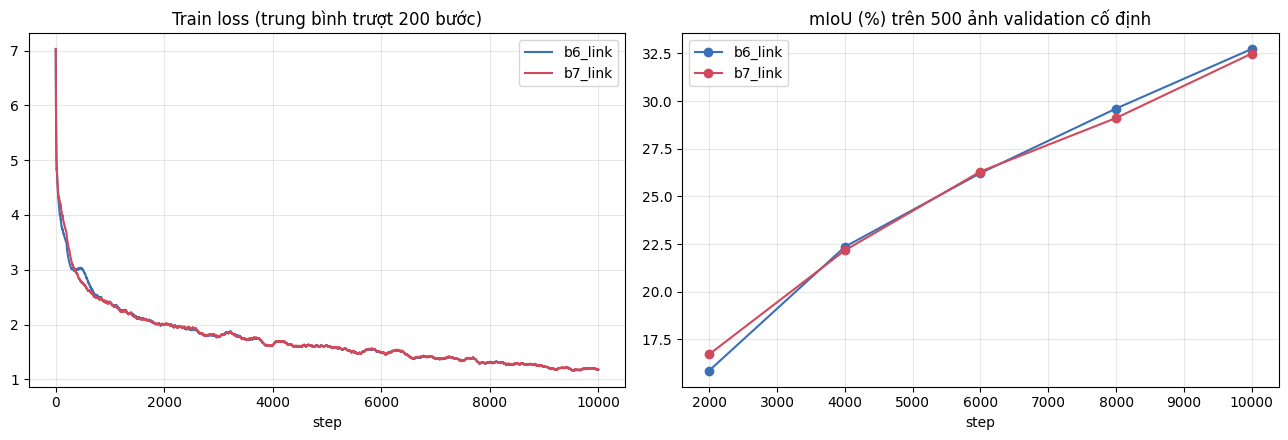

In [23]:
if not ENABLE_LINKS:
    print("ENABLE_LINKS = False: không có kết quả liên kết để phân tích.")
else:
    if str(WORK) not in sys.path:
        sys.path.insert(0, str(WORK))
    import pspnet_lab as lab

    rows = []
    for variant in LINK_VARIANTS:
        directory = RESULTS / f"{variant}_seed{seed}"
        metrics = json.loads((directory / "metrics.json").read_text(encoding="utf-8"))
        bench = [json.loads(p.read_text(encoding="utf-8")) for p in sorted(directory.glob("benchmark_repeat*.json"))]
        val = pd.read_csv(directory / "val_history.csv")
        rows.append({"variant": variant, "miou": metrics["miou"], "pixel_accuracy": metrics["pixel_accuracy"],
                     "val_subset_miou_final": val.val_subset_miou.iloc[-1],
                     "params_training": bench[0]["params_training"] if bench else np.nan,
                     "gmacs_conv_linear": bench[0]["gmacs_conv_linear"] if bench else np.nan,
                     "latency_ms_median": float(np.median([b["latency_ms_median"] for b in bench])) if bench else np.nan,
                     "training_hours": metrics["training_seconds"] / 3600})
    link_table = pd.DataFrame(rows)
    link_table.to_csv(RESULTS / "link_summary.csv", index=False)
    display(link_table)
    for r in link_table.itertuples():
        print(f"{r.variant}: mIoU = {100 * r.miou:.2f}% | pixel accuracy = {100 * r.pixel_accuracy:.2f}%")

    # b7_link - b6_link: hai bản cùng chạy ở đây nên so sánh ghép cặp theo ảnh được.
    files = [RESULTS / f"{v}_seed{seed}" / "per_image_stats_extension.npz" for v in LINK_VARIANTS]
    boot = pd.DataFrame([{"comparison": "b7_link - b6_link", **lab.paired_bootstrap(*files)}])
    boot.to_csv(RESULTS / "link_bootstrap.csv", index=False)
    display(boot.drop(columns=["scope"]))

    # Hệ số liên kết đã học: tanh(w) trong (-1, 1); gần 0 nghĩa là mô hình gần như không dùng cạnh đó.
    EDGES = [(0, 1), (1, 0), (1, 2), (2, 1), (2, 3), (3, 2)]  # cùng thứ tự với LinkedPPM.edges
    names = ["1×1", "2×2", "3×3", "nhánh cuối"]
    gate_rows = []
    for variant in LINK_VARIANTS:
        state = torch.load(checkpoint_path(variant, seed), map_location="cpu", weights_only=True, mmap=True)["model"]
        for (a, b), gate in zip(EDGES, torch.tanh(state["ppm.edge_weights"].float()).tolist()):
            gate_rows.append({"variant": variant, "edge": f"{names[a]} → {names[b]}", "tanh_w": gate})
    gates = pd.DataFrame(gate_rows)
    gates.to_csv(RESULTS / "link_gates.csv", index=False)
    display(gates.pivot(index="edge", columns="variant", values="tanh_w").round(4))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for variant, color in zip(LINK_VARIANTS, ["#3b6fb6", "#d1495b"]):
        directory = RESULTS / f"{variant}_seed{seed}"
        log = pd.read_csv(directory / "train.csv")
        val = pd.read_csv(directory / "val_history.csv")
        axes[0].plot(log.step, log.loss.rolling(200, min_periods=1).mean(), color=color, label=variant)
        axes[1].plot(val.step, 100 * val.val_subset_miou, "o-", color=color, label=variant)
    axes[0].set(title="Train loss (trung bình trượt 200 bước)", xlabel="step")
    axes[1].set(title=f"mIoU (%) trên {cfg['eval_subset']} ảnh validation cố định", xlabel="step")
    for ax in axes:
        ax.grid(alpha=.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS / "link_curves.png", dpi=150)
    plt.show()


## Lỗi thường gặp

| Lỗi | Xử lý |
|---|---|
| Thiếu GPU/BF16 | Chọn L4/A100 trong Compute profile và restart kernel |
| Volume chưa gắn | Attach Volume v2 đúng tên/mount path ở mục 2 |
| Google Drive giới hạn tải | Tải resnet101_v2.pth thủ công từ link trong lỗi, upload vào weights/ rồi chạy lại |
| Preflight OOM | Đặt `batch_size=8`, `accumulation=2` cho cả hai bản với `EXPERIMENT_NAME` mới |
| Lock/environment mismatch | Khôi phục môi trường/cấu hình cũ hoặc dùng output mới |
| Phiên bị ngắt | Giữ Volume; chạy lại notebook với cùng cấu hình, train tự resume checkpoint gần nhất |
| `last.pt` hỏng/không đọc được | `list_snapshots("b6", 17)` rồi `restore_snapshot("b6", 17, <bước>)`, chạy lại cell train |
| Muốn giữ bản sao ngoài Modal | `modal volume get <tên-volume> /results/<EXPERIMENT_NAME>/b6_seed17/snapshots ./backup` |
| Ảnh trùng train/validation | Đặc điểm của split ADE20K chính thức; xem `train_val_duplicates.json`, nêu trong báo cáo |
| Train quá lâu/tốn kém | Xem ETA trong log; nếu cần giảm `max_steps` cho **cả hai** bản với `EXPERIMENT_NAME` mới |
| Train acc/val mIoU không tăng | Dừng sớm; xem `train.csv` (loss, grad_norm, lr) và `val_history.csv` trước khi chạy tiếp |
| `chờ dữ liệu` lớn so với s/step | CPU là nút thắt: tăng số CPU cores trong Compute profile |

Notebook không tự kết luận cấu hình 7×7 tốt hơn, và chưa có kết quả ADE20K được điền sẵn.
